# Sanity test on language models

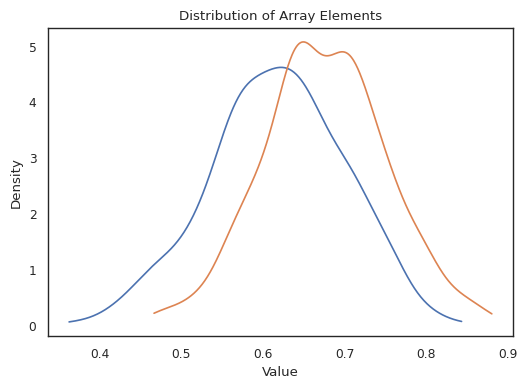

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

t = 'invertible'

sem_syn = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/pythia_160m/sem_syn.npy')
syn_syn = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/pythia_160m/syn_syn.npy')
sem_sem = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/pythia_160m/sem_sem.npy')
syn_sem = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/pythia_160m/syn_sem.npy')

plt.figure(figsize=(6, 4))

kde = gaussian_kde(sem_syn)
x = np.linspace(sem_syn.min(), sem_syn.max(), 500)
plt.plot(x, kde(x))

kde = gaussian_kde(syn_syn)
x = np.linspace(syn_syn.min(), syn_syn.max(), 500)
plt.plot(x, kde(x))

plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Distribution of Array Elements")

plt.show()

permutation
shape: (627,)
min/max: 0.9944886604107553 0.9986482483111939
std: 0.0005018100000435947

orthogonal
shape: (627,)
min/max: 0.9879967739914592 0.9980833461465549
std: 0.0011691747556163282

invertible
shape: (627,)
min/max: 0.3624683899591237 0.8431926851698059
std: 0.08219505804551369



Text(0.5, 0.01, 'Pairwise pearson correlation')

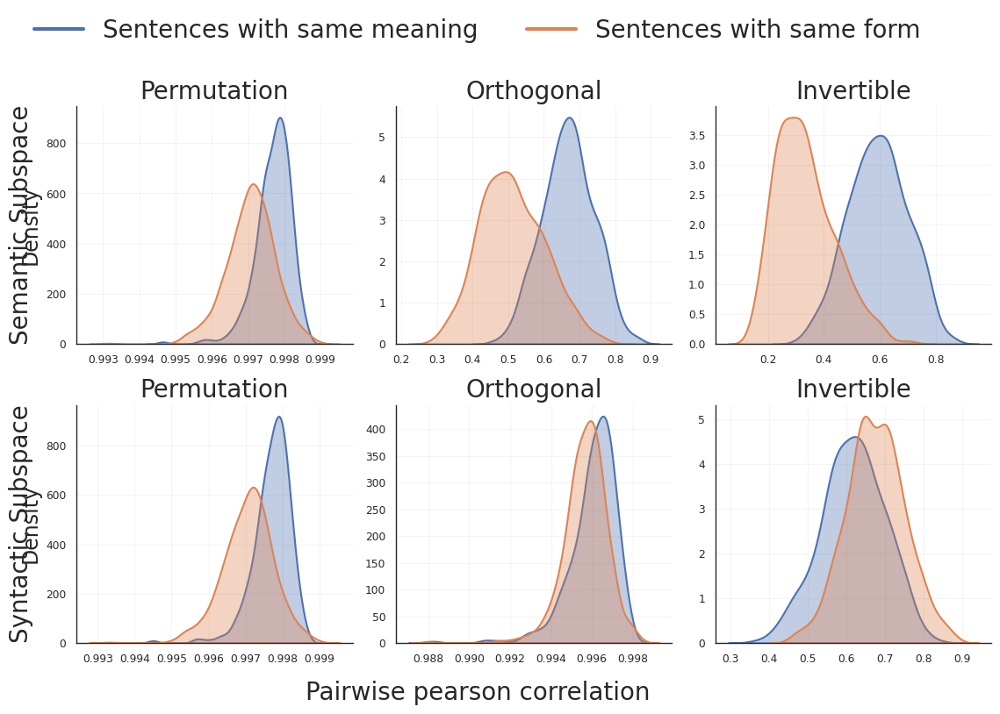

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

# --- Style ---
sns.set_theme(style="white", context="paper")

COLOR_SEMANTIC = "#4C72B0"
COLOR_SYNTACTIC   = "#DD8452"

model_name = 'pythia_160m'
types = ['permutation', 'orthogonal', 'invertible']

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=False, sharey=False)

for col, t in enumerate(types):
    # --- Load ---
    sem_syn = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/{model_name}/sem_syn.npy')
    syn_syn = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/{model_name}/syn_syn.npy')
    sem_sem = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/{model_name}/sem_sem.npy')
    syn_sem = np.load(f'inference_outputs/msr_paraphrase_corpus/{t}/{model_name}/syn_sem.npy')
    print(t)
    print("shape:", sem_syn.shape)
    print("min/max:", sem_syn.min(), sem_syn.max())
    print("std:", sem_syn.std())
    print()

    # =====================
    # Row 0: Semantic Units
    # =====================
    ax = axes[0, col]

    sns.kdeplot(sem_sem, ax=ax, color=COLOR_SEMANTIC, fill=True, alpha=0.35, linewidth=1.5)
    sns.kdeplot(syn_sem, ax=ax, color=COLOR_SYNTACTIC,   fill=True, alpha=0.35, linewidth=1.5)

    if col == 0:
        ax.set_ylabel("Density", fontsize=17)
    else:
        ax.set_ylabel("")
    # ax.tick_params(axis='y', labelsize=17)
    ax.set_title(t.capitalize(), pad=6, fontsize=20)
    # ax.set_xlabel("Pairwise correlation (same style images)")
    ax.grid(alpha=0.2)
    sns.despine(ax=ax)

    # =====================
    # Row 1: Syntactic Units
    # =====================
    ax = axes[1, col]

    sns.kdeplot(sem_syn, ax=ax, color=COLOR_SEMANTIC, fill=True, alpha=0.35, linewidth=1.5)
    sns.kdeplot(syn_syn, ax=ax, color=COLOR_SYNTACTIC,   fill=True, alpha=0.35, linewidth=1.5)
    
    if col == 0:
        ax.set_ylabel("Density", fontsize=17)
    else:
        ax.set_ylabel("")
    
    # ADD THIS LINE 👇
    ax.set_title(t.capitalize(), pad=6, fontsize=20)
    # ax.tick_params(axis='y', labelsize=17)
    ax.grid(alpha=0.2)
    sns.despine(ax=ax)

# --- Row labels (cleaner than repeating titles) ---
axes[0, 0].text(-0.2, 0.5, "Semantic Subspace", va='center', ha='center',
                rotation=90, fontsize=20, transform=axes[0, 0].transAxes)

axes[1, 0].text(-0.2, 0.5, "Syntactic Subspace", va='center', ha='center',
                rotation=90, fontsize=20, transform=axes[1, 0].transAxes)

# --- Global title ---
# fig.suptitle(
#     model_name.upper(),
#     fontsize=14,
#     fontweight='bold',
#     y=1.02
# )

# --- Shared legend ---
legend_elements = [
    Line2D([0], [0], color=COLOR_SEMANTIC, lw=3, label='Sentences with same meaning'),
    Line2D([0], [0], color=COLOR_SYNTACTIC,   lw=3, label='Sentences with same form')
]

fig.legend(
    handles=legend_elements,
    loc='upper center',   # moved to top
    ncol=2,
    frameon=False,
    fontsize=20,
    bbox_to_anchor=(0.5, 1.02)  # slightly above the figure
)

# adjust layout to make space for legend at top
plt.tight_layout(rect=[0.05, 0.05, 1, 0.92])
fig.supxlabel("Pairwise pearson correlation", fontsize=20)

# plt.savefig('neurips_2026_images/distribution_comp_main.pdf')

In [1]:
from utils.dataloader import *
from utils.models_util import *
from utils.loss_utils import *
import json

with open("raw_training_data/pereira_2018/syntactic_paraphrases_70_gemini.json", "r") as f:
    syntactic_paraphrases = json.load(f)

with open("raw_training_data/pereira_2018/paraphrases_70_gemini.json", "r") as f:
    paraphrases = json.load(f)

transformation_type = 'invertible'
hidden_state_level = 12
model_name = 'pythia_160m'

if transformation_type == 'permutation':
    print('Using Disentangled_Permutation_Language_Model')  
    model = Disentangled_Permutation_Language_Model(model_name, hidden_state_level, 'avg', 0.01, transformation_type).cuda()
else:
    print('Using Disentangled_Invertible_Language_Model')
    model = Disentangled_Invertible_Language_Model(model_name, hidden_state_level, 'avg', 0.01, transformation_type).cuda()

model.load_state_dict(
        torch.load(
            f"language_outputs/{transformation_type}/msr_paraphrase_corpus_{model_name}_0.01_{str(hidden_state_level)}_avg_{transformation_type}_0.4375_0.4375/last_best_model.pt"
        )
    )

semantic_percentage = 0.4375
syntactic_percentage = 0.4375
residual_percentage = 1 - semantic_percentage - syntactic_percentage

/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Using Disentangled_Invertible_Language_Model


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Using invertible transformation


In [2]:
from tqdm import tqdm

sem_syntactic = []
sem_semantic = []
syn_syntactic = []
syn_semantic = []

for id in tqdm(range(627)):
    org = paraphrases[str(id)]['original']
    sem = paraphrases[str(id)]['paraphrases']
    syn = syntactic_paraphrases[str(id)]['paraphrases']

    if transformation_type == "permutation":
        sem_outputs = model.inference_forward(sem)
    else:
        sem_outputs = model(sem)
    sem_outputs_semantic, sem_outputs_syntactic, sem_outputs_residual = torch.split(sem_outputs, [int(semantic_percentage*model.hidden_dim), int(syntactic_percentage*model.hidden_dim), int(residual_percentage*model.hidden_dim)], dim=1)
    sem_corr_syntactic  = np.corrcoef(sem_outputs_syntactic.cpu().detach().numpy()).mean()
    sem_corr_semantic  = np.corrcoef(sem_outputs_semantic.cpu().detach().numpy()).mean()
    
    if transformation_type == "permutation":
        syn_outputs = model.inference_forward(syn)
    else:
        syn_outputs = model(syn)
    syn_outputs_semantic, syn_outputs_syntactic, syn_outputs_residual = torch.split(syn_outputs, [int(semantic_percentage*model.hidden_dim), int(syntactic_percentage*model.hidden_dim), int(residual_percentage*model.hidden_dim)], dim=1)
    syn_corr_semantic  = np.corrcoef(syn_outputs_semantic.cpu().detach().numpy()).mean()
    syn_corr_syntactic  = np.corrcoef(syn_outputs_syntactic.cpu().detach().numpy()).mean()

    sem_syntactic.append(float(sem_corr_syntactic))
    sem_semantic.append(float(sem_corr_semantic))
    syn_syntactic.append(float(syn_corr_syntactic))
    syn_semantic.append(float(syn_corr_semantic))

    

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 627/627 [00:10<00:00, 57.24it/s]


In [3]:
out_dir = 'inference_outputs/msr_paraphrase_corpus/' + transformation_type + '/' + model_name + '/'
np.save(out_dir + 'sem_sem.npy', sem_semantic)
np.save(out_dir + 'sem_syn.npy',   sem_syntactic)
np.save(out_dir + 'syn_sem.npy', syn_semantic)
np.save(out_dir + 'syn_syn.npy',   syn_syntactic)

# Top 10 nearest neighbors - Vision

In [37]:
from utils.inference_dataloaders import *
from torchvision.models import *
import torch.nn as nn
from utils.models_util import *


resnet_model = resnet50(pretrained=True)
resnet_model = nn.Sequential(*list(resnet_model.children())[:-1])

params = {'batch_size': 1,
          'shuffle': True,
          'num_workers': 0}

all_set = Stylised_COCO_Conflicting_Cues()
all_generator = torch.utils.data.DataLoader(all_set,  **params)

model = Disentangled_Invertible_Visual_Model('swinb', 'invertible', None).cuda()
model.load_state_dict(torch.load('vision_outputs/invertible/mscoco_stylized_shape_texture_swinb_0.01_None_avg_invertible_0.4375_0.4375/last_best_model.pt'))


/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-base-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using invertible transformation


<All keys matched successfully>

In [38]:
from tqdm import tqdm

content_reps = []
content_labels = []

style_reps = []
style_labels = []

res_reps = []

org_reps = []

images = []

for X, content_label, style_label in tqdm(all_generator):
    with torch.no_grad():
        images.append(X.numpy())
        output = model(X.cuda())
        content_reps.append(output[:,:448].cpu().detach().numpy())
        style_reps.append(output[:,448:896].cpu().detach().numpy())
        res_reps.append(output[:,896:].cpu().detach().numpy())
        org_reps.append(X.cpu().detach().numpy())
        content_labels.append(list(content_label))
        style_labels.append(style_label)

content_reps = np.array(content_reps)
style_reps = np.array(style_reps)
content_labels = np.array(content_labels)
style_labels = np.array(style_labels)
res_reps = np.array(res_reps)
org_reps = np.array(org_reps)

content_reps = np.squeeze(content_reps)
style_reps = np.squeeze(style_reps)
res_reps = np.squeeze(res_reps)
org_reps = np.squeeze(org_reps)
content_labels = np.squeeze(content_labels)
style_labels = np.squeeze(style_labels)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [02:15<00:00, 73.57it/s]


In [48]:
import numpy as np

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def tensor_to_image(img):
    """
    img: numpy array in (3, H, W), ImageNet-normalized
    returns: (H, W, 3) in [0,1]
    """

    # CHW → HWC
    img = np.transpose(img, (1, 2, 0))

    # denormalize
    img = img * IMAGENET_STD + IMAGENET_MEAN

    # clip for display
    img = np.clip(img, 0, 1)

    return img

In [40]:


def get_nearest_100_neighbors(X, k=100):
    N = X.shape[0]
    neighbors = np.zeros((N, k), dtype=np.int32)

    # optionally normalize once if you want faster distance tricks
    X = X.astype(np.float32)

    for i in tqdm(range(N)):
        diff = X[i] - X              # (N, D)
        mse = np.mean(diff * diff, axis=1)  # (N,)

        # exclude self
        mse[i] = np.inf

        neighbors[i] = np.argpartition(mse, k)[:k]
        # optional: sort those k
        neighbors[i] = neighbors[i][np.argsort(mse[neighbors[i]])]

    return neighbors

style_nearest_neighbors = get_nearest_100_neighbors(style_reps)
content_nearest_neighbors = get_nearest_100_neighbors(content_reps)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:52<00:00, 189.59it/s]


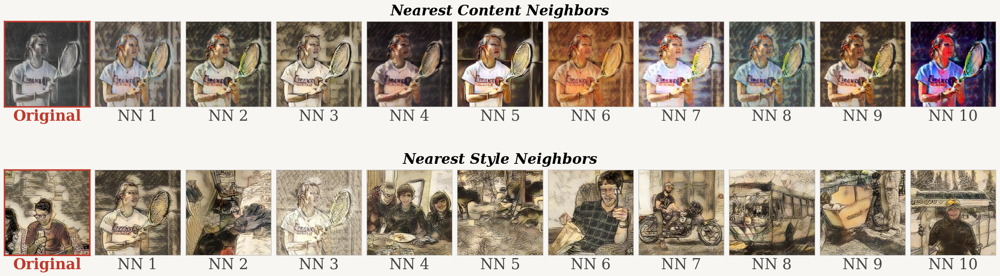

In [77]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def build_row(index, neighbors):
    original_image = tensor_to_image(org_reps[index])
    neighbor_indices = neighbors[index][:10]
    neighbor_images = [tensor_to_image(org_reps[i]) for i in neighbor_indices]
    images = [original_image] + neighbor_images
    titles = ["Original"] + [f"NN {i+1}" for i in range(len(neighbor_images))]
    return images, titles

content_imgs, content_titles = build_row(60, content_nearest_neighbors)
style_imgs, style_titles     = build_row(98, style_nearest_neighbors)

n_cols = len(content_imgs)

ACCENT = "#c0392b"

fig = plt.figure(figsize=(2.2 * n_cols, 8), facecolor="#f7f6f2")

gs = GridSpec(
    2, n_cols,
    figure=fig,
    hspace=0.0,
    wspace=0.06,
    left=0.02, right=0.98,
    top=0.92, bottom=0.05,
)

rows_cfg = [
    (content_imgs, content_titles, 0, "Nearest Content Neighbors"),
    (style_imgs,   style_titles,   1, "Nearest Style Neighbors"),
]

for imgs, titles, gs_row, label in rows_cfg:
    for c, (img, title) in enumerate(zip(imgs, titles)):
        ax = fig.add_subplot(gs[gs_row, c])
        ax.imshow(img, aspect="equal")
        ax.set_xticks([]); ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor(ACCENT if c == 0 else "#bbbbbb")
            spine.set_linewidth(2.5 if c == 0 else 0.8)

        ax.set_xlabel(
            title,
            fontsize=25, labelpad=3,
            color=ACCENT if c == 0 else "#444444",
            fontweight="bold" if c == 0 else "normal",
            fontfamily="serif",
        )

# --- draw titles AFTER all axes exist ---
fig.canvas.draw()

for gs_row, label in [(0, "Nearest Content Neighbors"), (1, "Nearest Style Neighbors")]:
    # get bounding box of the leftmost and rightmost axes in this row
    ax_left  = fig.axes[gs_row * n_cols]
    ax_right = fig.axes[gs_row * n_cols + n_cols - 1]

    pos_l = ax_left.get_position()
    pos_r = ax_right.get_position()

    x_center = (pos_l.x0 + pos_r.x1) / 2
    y_top    = pos_l.y1 + 0.01        # just above the images

    fig.text(
        x_center, y_top, label,
        ha="center", va="bottom",
        fontsize=24, fontweight="bold",
        fontfamily="serif", fontstyle="italic"
    )

plt.savefig("neurips_2026_images/retrieval_grid.pdf", dpi=180, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()

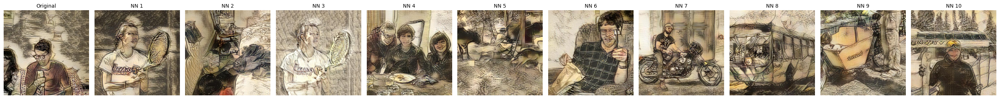

# Nearesr Neighbor - Language (Example)

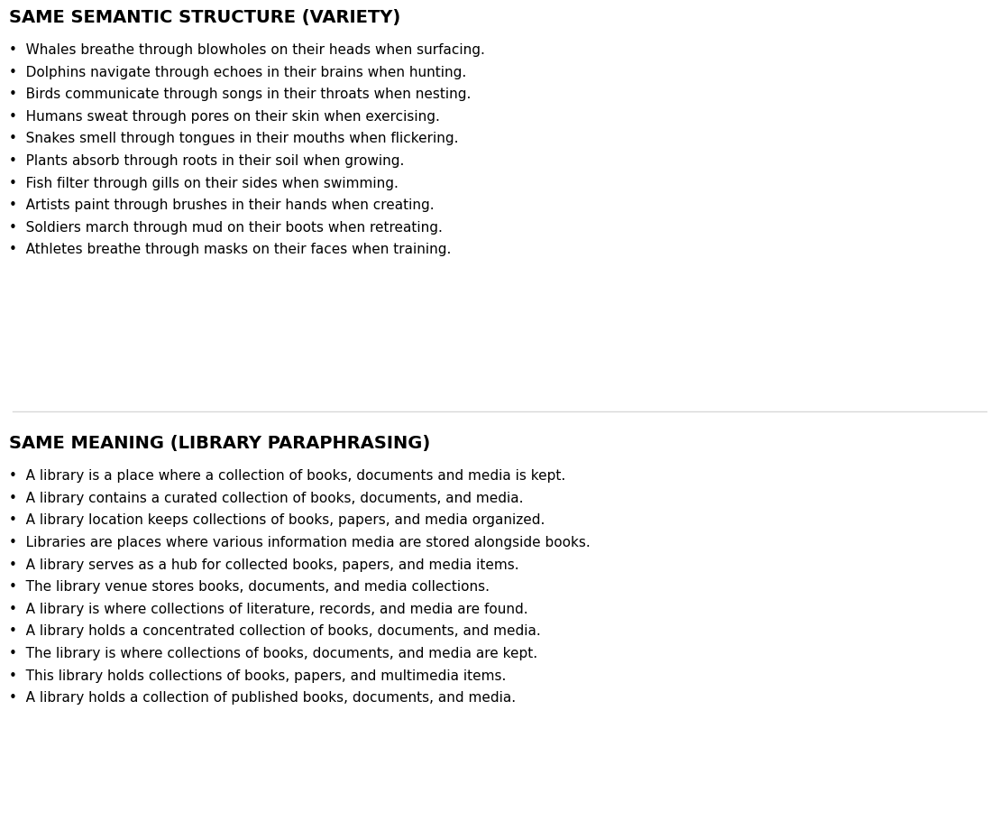

In [36]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------

SEMANTIC_VARIETY = [
    "Whales breathe through blowholes on their heads when surfacing.",
    "Dolphins navigate through echoes in their brains when hunting.",
    "Birds communicate through songs in their throats when nesting.",
    "Humans sweat through pores on their skin when exercising.",
    "Snakes smell through tongues in their mouths when flickering.",
    "Plants absorb through roots in their soil when growing.",
    "Fish filter through gills on their sides when swimming.",
    "Artists paint through brushes in their hands when creating.",
    "Soldiers march through mud on their boots when retreating.",
    "Athletes breathe through masks on their faces when training.",
]

LIBRARY_PARAPHRASES = [
    "A library is a place where a collection of books, documents and media is kept.",
    "A library contains a curated collection of books, documents, and media.",
    "A library location keeps collections of books, papers, and media organized.",
    "Libraries are places where various information media are stored alongside books.",
    "A library serves as a hub for collected books, papers, and media items.",
    "The library venue stores books, documents, and media collections.",
    "A library is where collections of literature, records, and media are found.",
    "A library holds a concentrated collection of books, documents, and media.",
    "The library is where collections of books, documents, and media are kept.",
    "This library holds collections of books, papers, and multimedia items.",
    "A library holds a collection of published books, documents, and media.",
]

DATA_BLOCKS = [
    ("Same Semantic Structure (Variety)", SEMANTIC_VARIETY),
    ("Same Meaning (Library Paraphrasing)", LIBRARY_PARAPHRASES),
]


# ---------------------------------------------------------------------------
# Rendering
# ---------------------------------------------------------------------------

def render_text_chart(data_blocks: list[tuple[str, list[str]]]) -> None:
    """
    Render a vertically stacked dual-pane text visualization.

    Parameters
    ----------
    data_blocks : list of (title, sentences) tuples
        Each tuple produces one panel in the figure.
    """
    n = len(data_blocks)
    fig, axes = plt.subplots(n, 1, figsize=(12, 10))

    # Ensure axes is always iterable, even for a single panel
    if n == 1:
        axes = [axes]

    for ax, (title, sentences) in zip(axes, data_blocks):
        ax.axis("off")

        body_text = "\n".join(f"\u2022  {s}" for s in sentences)

        # Title
        header = ax.text(
            0, 1.05, title.upper(),
            transform=ax.transAxes,
            fontsize=14, fontweight="bold", va="bottom",
        )

        # Body
        ax.text(
            0, 1.0, body_text,
            transform=ax.transAxes,
            fontsize=11, linespacing=1.8, va="top",
        )

        # Underline beneath the title
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        bbox = header.get_window_extent(renderer=renderer)
        inv = ax.transAxes.inverted()
        x0, y0 = inv.transform((bbox.x0, bbox.y0))
        x1, _  = inv.transform((bbox.x1, bbox.y0))
        ax.plot(
            [x0, x1], [y0 - 0.01, y0 - 0.01],
            transform=ax.transAxes,
            color="black", lw=1.5,
        )

    # Horizontal separator between panels
    separator = mlines.Line2D(
        [0.05, 0.95], [0.5, 0.5],
        transform=fig.transFigure,
        color="gray", alpha=0.3, lw=1.0,
    )
    fig.add_artist(separator)

    plt.tight_layout(pad=4.0)
    plt.savefig("neurips_2026_images/lang_dataset_examples.pdf", bbox_inches="tight")
    plt.show()


# ---------------------------------------------------------------------------
# Entry point
# ---------------------------------------------------------------------------

if __name__ == "__main__":
    render_text_chart(DATA_BLOCKS)

# Result 5 - Layerwise Comparisons

In [3]:
import numpy as np

base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl/'

syntax_semantic_47 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_47 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_47 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_47 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627


base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl_40/'

syntax_semantic_40 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_40 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_40 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_40 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627


base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl_30/'

syntax_semantic_30 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_30 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_30 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_30 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627


base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl_20/'

syntax_semantic_20 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_20 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_20 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_20 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627


base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl_10/'

syntax_semantic_10 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_10 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_10 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_10 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627


base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl_1/'

syntax_semantic_1 = np.load(base + 'syntax_units_semantic_selectivity.npy')/627
semantic_semantic_1 = np.load(base + 'semantic_units_semantic_selectivity.npy')/627

syntax_syntax_1 = np.load(base + 'syntax_units_syntax_selectivity.npy')/627
semantic_syntax_1 = np.load(base + 'semantic_units_syntax_selectivity.npy')/627

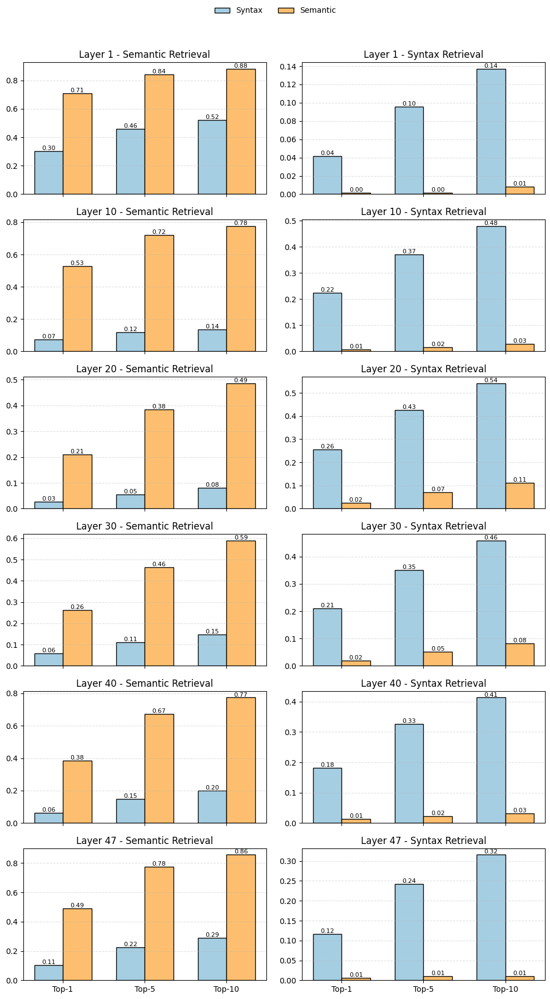

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Organize Data (no loading)
# -----------------------------
layers = [1, 10, 20, 30, 40, 47]

data = {
    1:  (syntax_semantic_1,  semantic_semantic_1,  syntax_syntax_1,  semantic_syntax_1),
    10: (syntax_semantic_10, semantic_semantic_10, syntax_syntax_10, semantic_syntax_10),
    20: (syntax_semantic_20, semantic_semantic_20, syntax_syntax_20, semantic_syntax_20),
    30: (syntax_semantic_30, semantic_semantic_30, syntax_syntax_30, semantic_syntax_30),
    40: (syntax_semantic_40, semantic_semantic_40, syntax_syntax_40, semantic_syntax_40),
    47: (syntax_semantic_47, semantic_semantic_47, syntax_syntax_47, semantic_syntax_47),
}

# -----------------------------
# Config
# -----------------------------
labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.35

color_syntax = '#a6cee3'
color_semantic = '#fdbf6f'

# -----------------------------
# Plot (6 x 2)
# -----------------------------
fig, axes = plt.subplots(len(layers), 2, figsize=(10, 18), sharex=True)

for i, layer in enumerate(layers):

    syntax_sem, semantic_sem, syntax_syn, semantic_syn = data[layer]

    # ---- Semantic (left)
    ax = axes[i, 0]
    b1 = ax.bar(x - width/2, syntax_sem, width, color=color_syntax, edgecolor='black')
    b2 = ax.bar(x + width/2, semantic_sem, width, color=color_semantic, edgecolor='black')

    ax.set_title(f'Layer {layer} - Semantic Retrieval')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    # if i == 0:
    #     ax.set_ylabel('Score')

    for bars in [b1, b2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h,
                    f'{h:.2f}', ha='center', va='bottom', fontsize=8)

    # ---- Syntax (right)
    ax = axes[i, 1]
    b1 = ax.bar(x - width/2, syntax_syn, width, color=color_syntax, edgecolor='black')
    b2 = ax.bar(x + width/2, semantic_syn, width, color=color_semantic, edgecolor='black')

    ax.set_title(f'Layer {layer} - Syntax Retrieval')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    for bars in [b1, b2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h,
                    f'{h:.2f}', ha='center', va='bottom', fontsize=8)

# -----------------------------
# Legend
# -----------------------------
handles = [
    plt.Rectangle((0,0),1,1,color=color_syntax, ec='black'),
    plt.Rectangle((0,0),1,1,color=color_semantic, ec='black')
]

fig.legend(handles, ['Syntax', 'Semantic'],
           loc='upper center', ncol=2, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('neurips_2026_images/all_layers_comp.pdf')
plt.show()

# Results 4 - Retrieval Results with Language

In [1]:
from utils.dataloader import *
from utils.models_util import *
from utils.loss_utils import *

import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

with open("raw_training_data/pereira_2018/syntactic_paraphrases_70_gemini.json", "r") as f:
    syntactic_paraphrases = json.load(f)

with open("raw_training_data/pereira_2018/paraphrases_70_gemini.json", "r") as f:
    paraphrases = json.load(f)

layer = 23
transformation_type = 'invertible'
model_name = 'pythia_410m'

model = Disentangled_Invertible_Language_Model(model_name, layer, 'avg', 0.01, transformation_type).cuda()
model.load_state_dict(torch.load('language_outputs/invertible/msr_paraphrase_corpus_'+model_name+'_0.01_'+str(layer)+'_avg_'+transformation_type+'_0.4375_0.4375/last_best_model.pt'))

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Using invertible transformation


<All keys matched successfully>

In [2]:
### no.of common tokens

semantic_tokens_ovelap = []
syntactic_tokens_overlap = []

def count_matching_nonzero(tensor, i):
    """
    Compare row[0] with row[i]: count positions where both values are equal and non-zero.
    """
    row0 = tensor[0]
    rowi = tensor[i]
    
    mask = (row0 == rowi) & (row0 != 0)
    return mask.sum().item()


for i in paraphrases:
    semantic_sentences = [paraphrases[str(i)]['original']] + paraphrases[str(i)]['paraphrases']
    encoded_inputs1 = model.tokenizer(semantic_sentences, return_tensors='pt', padding=True)
    x = encoded_inputs1['input_ids']
    counts = [count_matching_nonzero(x,i) for i in range(1,71)]
    semantic_tokens_ovelap=semantic_tokens_ovelap+counts
    syntactic_sentences = [syntactic_paraphrases[str(i)]['original']] + syntactic_paraphrases[str(i)]['paraphrases']
    encoded_inputs1 = model.tokenizer(syntactic_sentences, return_tensors='pt', padding=True)
    x = encoded_inputs1['input_ids']
    counts = [count_matching_nonzero(x,i) for i in range(1,71)]
    syntactic_tokens_overlap=syntactic_tokens_overlap+counts

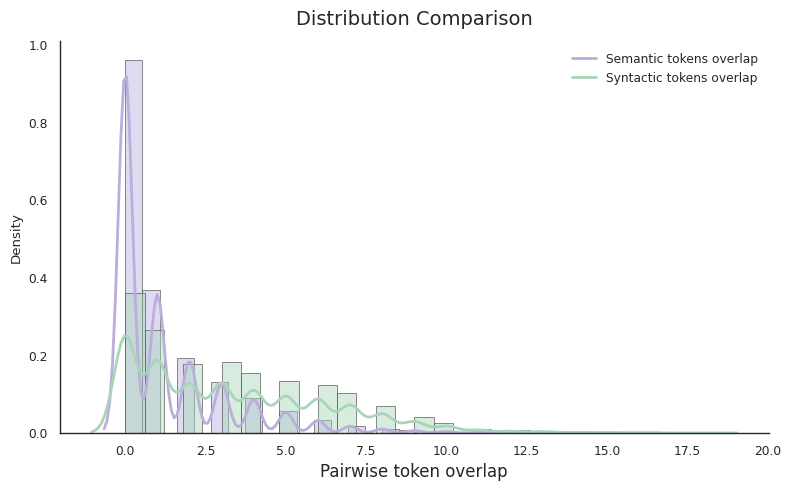

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", context="paper")

# -----------------------------
# Pastel lavender & green
# -----------------------------
color_semantic = "#B9AEDC"  # soft lavender
color_syntactic = "#A8D5BA"  # soft pastel green
edge_color = "#5A5A5A"

plt.figure(figsize=(8, 5))

# -----------------------------
# Distribution plots
# -----------------------------
sns.histplot(semantic_tokens_ovelap, bins=30, stat="density",
             color=color_semantic, alpha=0.45,
             edgecolor=edge_color, linewidth=0.5)

sns.kdeplot(semantic_tokens_ovelap, color=color_semantic, linewidth=2)

sns.histplot(syntactic_tokens_overlap, bins=30, stat="density",
             color=color_syntactic, alpha=0.45,
             edgecolor=edge_color, linewidth=0.5)

sns.kdeplot(syntactic_tokens_overlap, color=color_syntactic, linewidth=2)

# -----------------------------
# Aesthetics
# -----------------------------
plt.title("Distribution Comparison", fontsize=14, pad=12)
plt.xlabel("Pairwise token overlap", fontsize=12)

sns.despine()

plt.legend(
    ["Semantic tokens overlap", "Syntactic tokens overlap"],
    frameon=False
)

plt.tight_layout()
plt.savefig('neurips_2026_images/token_overlap.pdf')
plt.show()

In [4]:
### Print top 10 syntax and semantic neighbors


import random
from tqdm import tqdm 

def get_topk_neighbors(x, Y, k=10):
    # Compute L2 distances
    dists = torch.norm(Y - x.unsqueeze(0), dim=1)  # (A,)

    # Get top-k smallest distances
    topk_dists, topk_indices = torch.topk(dists, k, largest=False)

    return topk_indices

indices = [51+i*50 for i in range(10)]

sentences = [paraphrases[str(i)]['original'] for i in indices]
for i in indices:
    sentences=sentences+paraphrases[str(i)]['paraphrases']
    sentences=sentences+syntactic_paraphrases[str(i)]['paraphrases']



with torch.no_grad():
    outputs = model(sentences)
    outputs_semantic, outputs_syntactic, outputs_residual = torch.split(outputs, [int(0.4375*model.hidden_dim), int(0.4375*model.hidden_dim), int(0.125*model.hidden_dim)], dim=1)

sem_nearest_indices = get_topk_neighbors(outputs_semantic[0], outputs_semantic[1:])
syn_nearest_indices = get_topk_neighbors(outputs_syntactic[0], outputs_syntactic[1:])
    

In [6]:
sentences[0], [sentences[1:][i] for i in sem_nearest_indices]
sentences[0], [sentences[1:][i] for i in syn_nearest_indices]

('When I use the riding lawn mower, the uncomfortable chair makes my back hurt.',
 ['The stiff seat on the riding mower hurts my back while mowing.',
  'Using the riding mower, the bad seat causes back pain.',
  "The mower's bad seat gives me back discomfort when I use it.",
  'The mower seat is uncomfortable and makes my back hurt.',
  'Using the rider, the awful seat makes my back hurt later.',
  'Riding the mower means my back hurts from the seat.',
  'When I use the rowing machine, the wooden seat makes my glutes sore.',
  'The riding mower chair hurts my back while I use it.',
  "The riding mower's stiff seat gives me back pain.",
  'The chair on the riding mower is uncomfortable and hurts my back.'])

In [10]:
import random
from tqdm import tqdm 

def get_topk_neighbors(x, Y, k=10):
    # Compute L2 distances
    dists = torch.norm(Y - x.unsqueeze(0), dim=1)  # (A,)

    # Get top-k smallest distances
    topk_dists, topk_indices = torch.topk(dists, k, largest=False)

    return topk_indices

sem_acc_1 = 0.0
syn_acc_1 = 0.0
org_acc_1 = 0.0

sem_acc_5 = 0.0
syn_acc_5 = 0.0
org_acc_5 = 0.0

sem_acc_10 = 0.0
syn_acc_10 = 0.0
org_acc_10 = 0.0

for id in tqdm(range(627)):
    original = paraphrases[str(id)]['original']
    sem = random.choice(paraphrases[str(id)]['paraphrases'])
    syn = syntactic_paraphrases[str(id)]['paraphrases']
    sentences = [original, sem] + syn
    labels = [1,1] + [0 for i in syn] 
    with torch.no_grad():
        outputs = model.llm_forward(sentences)
        # outputs_semantic, outputs_syntactic, outputs_residual = torch.split(outputs, [int(0.4375*model.hidden_dim), int(0.4375*model.hidden_dim), int(0.125*model.hidden_dim)], dim=1)
    
    labels = torch.tensor(labels)
    # sem_nearest_indices = get_topk_neighbors(outputs_semantic[0], outputs_semantic[1:])
    # nearest_sem_labels = labels[1:][sem_nearest_indices.cpu()]
    # syn_nearest_indices = get_topk_neighbors(outputs_syntactic[0], outputs_syntactic[1:])
    # nearest_syn_labels = labels[1:][syn_nearest_indices.cpu()]
    org_nearest_indices = get_topk_neighbors(outputs[0], outputs[1:])
    nearest_org_labels = labels[1:][org_nearest_indices.cpu()]

    # if nearest_sem_labels[0] == 1:
    #     sem_acc_1+= 1.0
    # if nearest_syn_labels[0] == 1:
    #     syn_acc_1+= 1.0
    if nearest_org_labels[0] == 1:
        org_acc_1+= 1.0

    # if 1 in nearest_sem_labels[:5]:
    #     sem_acc_5+= 1.0
    # if 1 in nearest_syn_labels[:5]:
    #     syn_acc_5+= 1.0
    if 1 in nearest_org_labels[:5]:
        org_acc_5+= 1.0

    # if 1 in nearest_sem_labels[:10]:
    #     sem_acc_10+= 1.0
    # if 1 in nearest_syn_labels[:10]:
    #     syn_acc_10+= 1.0
    if 1 in nearest_org_labels[:10]:
        org_acc_10+= 1.0

syntax_acc = [syn_acc_1, syn_acc_5, syn_acc_10]
semantic_acc = [sem_acc_1, sem_acc_5, sem_acc_10]
original_acc = [org_acc_1, org_acc_5, org_acc_10]

# np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name+'_'+str(layer)+'/syntax_units_semantic_selectivity.npy', syntax_acc)
# np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name+'_'+str(layer)+'/semantic_units_semantic_selectivity.npy', semantic_acc)
np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name + '/original_units_semantic_selectivity.npy', original_acc)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 627/627 [01:10<00:00,  8.85it/s]


In [11]:
import random
from tqdm import tqdm 

def get_topk_neighbors(x, Y, k=10):
    # Compute L2 distances
    dists = torch.norm(Y - x.unsqueeze(0), dim=1)  # (A,)

    # Get top-k smallest distances
    topk_dists, topk_indices = torch.topk(dists, k, largest=False)

    return topk_indices

sem_acc_1 = 0.0
syn_acc_1 = 0.0
org_acc_1 = 0.0

sem_acc_5 = 0.0
syn_acc_5 = 0.0
org_acc_5 = 0.0

sem_acc_10 = 0.0
syn_acc_10 = 0.0
org_acc_10 = 0.0

for id in tqdm(range(627)):
    original = paraphrases[str(id)]['original']
    sem = paraphrases[str(id)]['paraphrases']
    syn = random.choice(syntactic_paraphrases[str(id)]['paraphrases'])
    sentences = [original, syn] + sem
    labels = [1,1] + [0 for i in sem] 
    with torch.no_grad():
        outputs = model.llm_forward(sentences)
        # outputs_semantic, outputs_syntactic, outputs_residual = torch.split(outputs, [int(0.4375*model.hidden_dim), int(0.4375*model.hidden_dim), int(0.125*model.hidden_dim)], dim=1)
    
    labels = torch.tensor(labels)
    # sem_nearest_indices = get_topk_neighbors(outputs_semantic[0], outputs_semantic[1:])
    # nearest_sem_labels = labels[1:][sem_nearest_indices.cpu()]
    # syn_nearest_indices = get_topk_neighbors(outputs_syntactic[0], outputs_syntactic[1:])
    # nearest_syn_labels = labels[1:][syn_nearest_indices.cpu()]
    org_nearest_indices = get_topk_neighbors(outputs[0], outputs[1:])
    nearest_org_labels = labels[1:][org_nearest_indices.cpu()]

    # if nearest_sem_labels[0] == 1:
    #     sem_acc_1+= 1.0
    # if nearest_syn_labels[0] == 1:
    #     syn_acc_1+= 1.0
    if nearest_org_labels[0] == 1:
        org_acc_1+= 1.0

    # if 1 in nearest_sem_labels[:5]:
    #     sem_acc_5+= 1.0
    # if 1 in nearest_syn_labels[:5]:
    #     syn_acc_5+= 1.0
    if 1 in nearest_org_labels[:5]:
        org_acc_5+= 1.0

    # if 1 in nearest_sem_labels[:10]:
    #     sem_acc_10+= 1.0
    # if 1 in nearest_syn_labels[:10]:
    #     syn_acc_10+= 1.0
    if 1 in nearest_org_labels[:10]:
        org_acc_10+= 1.0

syntax_acc = [syn_acc_1, syn_acc_5, syn_acc_10]
semantic_acc = [sem_acc_1, sem_acc_5, sem_acc_10]
original_acc = [org_acc_1, org_acc_5, org_acc_10]

# np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name+'_'+str(layer)+'/syntax_units_syntax_selectivity.npy', syntax_acc)
# np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name+'_'+str(layer)+'/semantic_units_syntax_selectivity.npy', semantic_acc)
np.save('inference_outputs/pereira_cross_sanity/' + transformation_type + '/'+model_name+'/original_units_syntax_selectivity.npy', original_acc)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 627/627 [01:04<00:00,  9.72it/s]


In [25]:
outputs.shape

torch.Size([72, 1600])

In [30]:
A = np.concatenate((permutation_syntax_selectivity,permutation_semantic_selectivity))
print('  & '.join(f"{x:.4f}" for x in A))

0.1707  & 0.1418  & 0.1271  & 0.0357  & 0.0563  & 0.0861


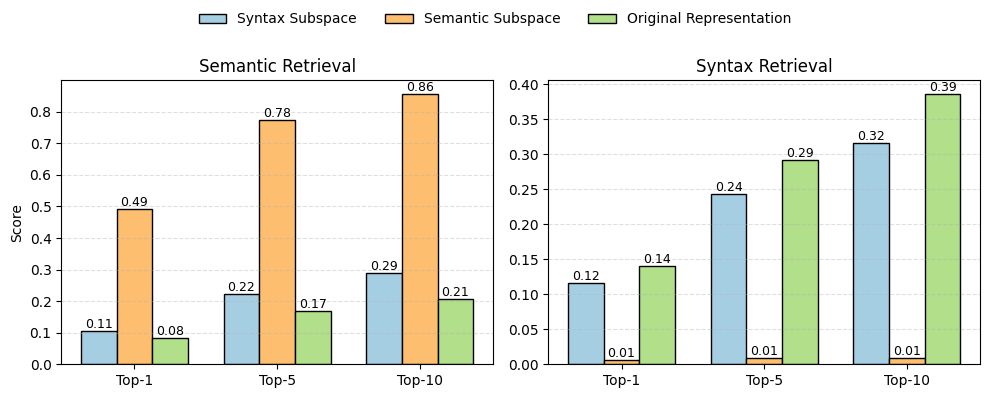

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Config
# -----------------------------
labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.25

# Colors (pastel)
color_syntax   = '#a6cee3'   # pastel blue
color_semantic = '#fdbf6f'   # pastel orange
color_original = '#b2df8a'   # pastel green

# -----------------------------
# Load Invertible Data
# -----------------------------
base = 'inference_outputs/pereira_cross_sanity/invertible/gpt2_xl/'

syntax_semantic   = np.load(base + 'syntax_units_semantic_selectivity.npy') / 627
semantic_semantic = np.load(base + 'semantic_units_semantic_selectivity.npy') / 627
original_semantic = np.load(base + 'original_units_semantic_selectivity.npy') / 627

syntax_syntax   = np.load(base + 'syntax_units_syntax_selectivity.npy') / 627
semantic_syntax = np.load(base + 'semantic_units_syntax_selectivity.npy') / 627
original_syntax = np.load(base + 'original_units_syntax_selectivity.npy') / 627

# -----------------------------
# Create Figure (1x2)
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)

# -----------------------------
# Left: Semantic Selectivity
# -----------------------------
ax = axes[0]

bars1 = ax.bar(
    x - width,
    syntax_semantic,
    width,
    label='Syntax Subspace',
    color=color_syntax,
    edgecolor='black'
)

bars2 = ax.bar(
    x,
    semantic_semantic,
    width,
    label='Semantic Subspace',
    color=color_semantic,
    edgecolor='black'
)

bars3 = ax.bar(
    x + width,
    original_semantic,
    width,
    label='Original Representation',
    color=color_original,
    edgecolor='black'
)

ax.set_title('Semantic Retrieval')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Score')
ax.grid(axis='y', linestyle='--', alpha=0.4)

# annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

# -----------------------------
# Right: Syntax Selectivity
# -----------------------------
ax = axes[1]

bars1 = ax.bar(
    x - width,
    syntax_syntax,
    width,
    label='Syntax',
    color=color_syntax,
    edgecolor='black'
)

bars2 = ax.bar(
    x,
    semantic_syntax,
    width,
    label='Semantic',
    color=color_semantic,
    edgecolor='black'
)

bars3 = ax.bar(
    x + width,
    original_syntax,
    width,
    label='Original',
    color=color_original,
    edgecolor='black'
)

ax.set_title('Syntax Retrieval')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis='y', linestyle='--', alpha=0.4)

# annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

# -----------------------------
# Legend + Layout
# -----------------------------
handles, labels_legend = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels_legend,
    loc='upper center',
    ncol=3,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.9])

# plt.savefig('neurips_2026_images/syn_sem_gpt2xl.pdf')
plt.show()

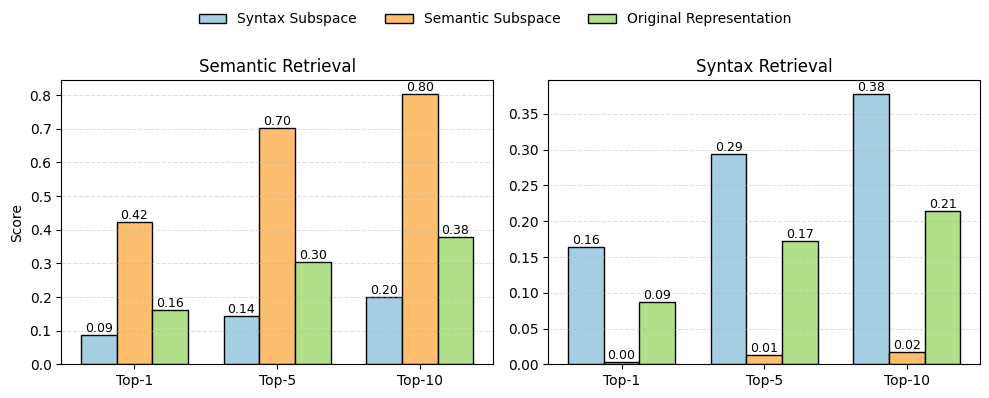

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Config
# -----------------------------
labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.25

# Colors (pastel)
color_syntax   = '#a6cee3'   # pastel blue
color_semantic = '#fdbf6f'   # pastel orange
color_original = '#b2df8a'   # pastel green

# -----------------------------
# Load Invertible Data
# -----------------------------
base = 'inference_outputs/pereira_cross_sanity/invertible/pythia_160m/'

syntax_semantic   = np.load(base + 'syntax_units_semantic_selectivity.npy') / 627
semantic_semantic = np.load(base + 'semantic_units_semantic_selectivity.npy') / 627
original_semantic = np.load(base + 'original_units_semantic_selectivity.npy') / 627

syntax_syntax   = np.load(base + 'syntax_units_syntax_selectivity.npy') / 627
semantic_syntax = np.load(base + 'semantic_units_syntax_selectivity.npy') / 627
original_syntax = np.load(base + 'original_units_syntax_selectivity.npy') / 627

# -----------------------------
# Create Figure (1x2)
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)

# -----------------------------
# Left: Semantic Selectivity
# -----------------------------
ax = axes[0]

bars1 = ax.bar(
    x - width,
    syntax_semantic,
    width,
    label='Syntax Subspace',
    color=color_syntax,
    edgecolor='black'
)

bars2 = ax.bar(
    x,
    semantic_semantic,
    width,
    label='Semantic Subspace',
    color=color_semantic,
    edgecolor='black'
)

bars3 = ax.bar(
    x + width,
    original_semantic,
    width,
    label='Original Representation',
    color=color_original,
    edgecolor='black'
)

ax.set_title('Semantic Retrieval')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Score')
ax.grid(axis='y', linestyle='--', alpha=0.4)

# annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

# -----------------------------
# Right: Syntax Selectivity
# -----------------------------
ax = axes[1]

bars1 = ax.bar(
    x - width,
    syntax_syntax,
    width,
    label='Syntax',
    color=color_syntax,
    edgecolor='black'
)

bars2 = ax.bar(
    x,
    semantic_syntax,
    width,
    label='Semantic',
    color=color_semantic,
    edgecolor='black'
)

bars3 = ax.bar(
    x + width,
    original_syntax,
    width,
    label='Original',
    color=color_original,
    edgecolor='black'
)

ax.set_title('Syntax Retrieval')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis='y', linestyle='--', alpha=0.4)

# annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

# -----------------------------
# Legend + Layout
# -----------------------------
handles, labels_legend = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels_legend,
    loc='upper center',
    ncol=3,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.9])

plt.savefig('neurips_2026_images/syn_sem_pythia_160m.pdf')
plt.show()

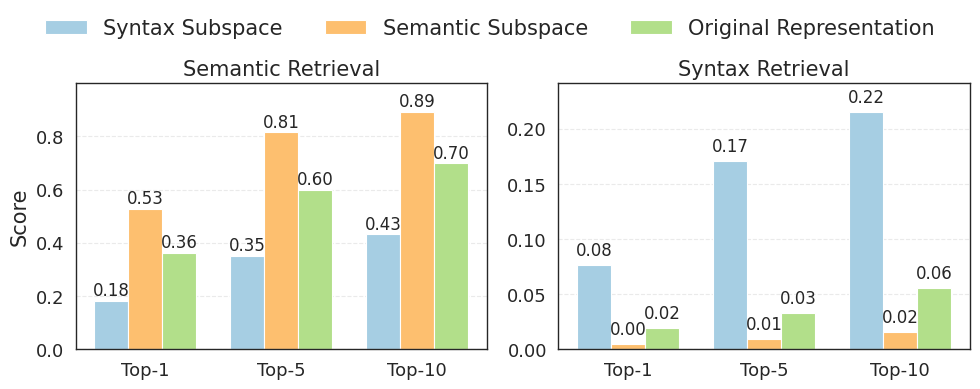

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Config
# -----------------------------
labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.25

# Colors (pastel)
color_syntax   = '#a6cee3'
color_semantic = '#fdbf6f'
color_original = '#b2df8a'

# -----------------------------
# Load Invertible Data
# -----------------------------
base = 'inference_outputs/pereira_cross_sanity/invertible/pythia_410m/'

syntax_semantic   = np.load(base + 'syntax_units_semantic_selectivity.npy') / 627
semantic_semantic = np.load(base + 'semantic_units_semantic_selectivity.npy') / 627
original_semantic = np.load(base + 'original_units_semantic_selectivity.npy') / 627

syntax_syntax   = np.load(base + 'syntax_units_syntax_selectivity.npy') / 627
semantic_syntax = np.load(base + 'semantic_units_syntax_selectivity.npy') / 627
original_syntax = np.load(base + 'original_units_syntax_selectivity.npy') / 627

# -----------------------------
# Create Figure (1x2)
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)

# -----------------------------
# Left: Semantic Selectivity
# -----------------------------
ax = axes[0]

bars1 = ax.bar(
    x - width,
    syntax_semantic,
    width,
    label='Syntax Subspace',
    color=color_syntax
)

bars2 = ax.bar(
    x,
    semantic_semantic,
    width,
    label='Semantic Subspace',
    color=color_semantic
)

bars3 = ax.bar(
    x + width,
    original_semantic,
    width,
    label='Original Representation',
    color=color_original
)

ax.set_title('Semantic Retrieval', fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Score', fontsize=15)

# Increase x/y tick fontsize
ax.tick_params(axis='both', labelsize=13)

# Add vertical breathing room above annotations
ax.margins(y=0.12)

ax.grid(axis='y', linestyle='--', alpha=0.4)

# Annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.005,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=12
        )

# -----------------------------
# Right: Syntax Selectivity
# -----------------------------
ax = axes[1]

bars1 = ax.bar(
    x - width,
    syntax_syntax,
    width,
    label='Syntax',
    color=color_syntax
)

bars2 = ax.bar(
    x,
    semantic_syntax,
    width,
    label='Semantic',
    color=color_semantic
)

bars3 = ax.bar(
    x + width,
    original_syntax,
    width,
    label='Original',
    color=color_original
)

ax.set_title('Syntax Retrieval', fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(labels)

# Increase x/y tick fontsize
ax.tick_params(axis='both', labelsize=13)

# Add vertical breathing room above annotations
ax.margins(y=0.12)

ax.grid(axis='y', linestyle='--', alpha=0.4)

# Annotate
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.005,
            f'{h:.2f}',
            ha='center',
            va='bottom',
            fontsize=12
        )

# -----------------------------
# Legend + Layout
# -----------------------------
handles, labels_legend = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels_legend,
    loc='upper center',
    ncol=3,
    frameon=False,
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.9], pad=1.5)

plt.savefig(
    'neurips_2026_images/syn_sem_pythia_410m.pdf',
    bbox_inches='tight'
)

plt.show()

# Results 2a - Ablation with different number of units

In [4]:
from utils.dataloader import *
from utils.models_util import *
from utils.train_utils import *
from utils.inference_dataloaders import *
import torch.nn.functional as F
from itertools import islice
from tqdm import tqdm
import argparse
import logging
import random
import os


def get_nearest_10_neighbors(X, k=100):
    N = X.shape[0]
    neighbors = np.zeros((N, k), dtype=np.int32)
    X = X.astype(np.float32)
    for i in tqdm(range(N)):
        diff = X[i] - X
        mse = np.mean(diff * diff, axis=1)
        mse[i] = np.inf
        neighbors[i] = np.argpartition(mse, k)[:k]
        neighbors[i] = neighbors[i][np.argsort(mse[neighbors[i]])]
    return neighbors


def get_topk_accuracy(neighbors, k, content_labels, style_labels):
    top_k_content = 0.0
    top_k_style   = 0.0
    pred_content   = content_labels[neighbors]
    pred_style     = style_labels[neighbors]
    for i in tqdm(range(len(pred_content))):
        if content_labels[i] in pred_content[i][:k]:
            top_k_content += 1.0
        if style_labels[i] in pred_style[i][: k]:
            top_k_style += 1.0
    return top_k_content / 10000, top_k_style / 10000

In [7]:
model_name = 'swinb'

content_units = 0.5
style_units = 0.5
res_units = 1 - content_units - style_units

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ── Model ────────────────────────────────────────────────────────────────

model = Disentangled_Invertible_Visual_Model(model_name, 'invertible', None).cuda()
model.load_state_dict(
    torch.load(
        f"vision_outputs/invertible/mscoco_stylized_shape_texture_{model_name}_0.01_None_avg_invertible_{str(content_units)}_{str(style_units)}/last_best_model.pt"
    )
)

# ── Dataloader ───────────────────────────────────────────────────────────
params = {"batch_size": 1, "shuffle": True, "num_workers": 0}
all_set = Stylised_COCO_Conflicting_Cues()
all_generator = torch.utils.data.DataLoader(all_set, **params)

# ── Feature extraction ───────────────────────────────────────────────────
content_reps, content_labels = [], []
style_reps, style_labels = [], []
res_reps, images = [], []

for X, content_label, style_label in tqdm(all_generator):
    with torch.no_grad():
        images.append(X.numpy())
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
            output,
            [
                int(content_units * model.hidden_dim),
                int(style_units * model.hidden_dim),
                int(res_units  * model.hidden_dim),
            ],
            dim=1,
        )
        content_reps.append(content_rep.cpu().detach().numpy())
        style_reps.append(style_rep.cpu().detach().numpy())
        res_reps.append(res_rep.cpu().detach().numpy())
        content_labels.append(list(content_label))
        style_labels.append(style_label)

content_reps   = np.squeeze(np.array(content_reps))
style_reps     = np.squeeze(np.array(style_reps))
res_reps       = np.squeeze(np.array(res_reps))
content_labels = np.squeeze(np.array(content_labels))
style_labels   = np.squeeze(np.array(style_labels))

# ── Nearest-neighbour search ──────────────────────────────────────────────
style_nearest_neighbors   = get_nearest_10_neighbors(style_reps)
content_nearest_neighbors = get_nearest_10_neighbors(content_reps)
res_nearest_neighbors     = get_nearest_10_neighbors(res_reps)

# ── Accuracy computation ──────────────────────────────────────────────────
results = {
    "style": {
        10: get_topk_accuracy(style_nearest_neighbors,   10, content_labels, style_labels),
        5:  get_topk_accuracy(style_nearest_neighbors,   5,  content_labels, style_labels),
        1:  get_topk_accuracy(style_nearest_neighbors,   1,  content_labels, style_labels),
    },
    "content": {
        10: get_topk_accuracy(content_nearest_neighbors, 10, content_labels, style_labels),
        5:  get_topk_accuracy(content_nearest_neighbors, 5,  content_labels, style_labels),
        1:  get_topk_accuracy(content_nearest_neighbors, 1,  content_labels, style_labels),
    },
    "res": {
        10: get_topk_accuracy(res_nearest_neighbors,     10, content_labels, style_labels),
        5:  get_topk_accuracy(res_nearest_neighbors,     5,  content_labels, style_labels),
        1:  get_topk_accuracy(res_nearest_neighbors,     1,  content_labels, style_labels),
    },
}

# ── Save results ──────────────────────────────────────────────────────────
out_dir = f"inference_outputs/mscoco_retrieval_results/invertible/{str(content_units)}_{str(style_units)}/{model_name}"
os.makedirs(out_dir, exist_ok=True)

for unit_type, k_dict in results.items():
    for k, (content_acc, style_acc) in k_dict.items():
        np.save(os.path.join(out_dir, f"{unit_type}_units_content_acc_{k}.npy"), content_acc)
        np.save(os.path.join(out_dir, f"{unit_type}_units_style_acc_{k}.npy"),   style_acc)

print(f"\nDone. Results saved to {out_dir}")

Using invertible transformation


  0%|                                                                                                                                                                           | 0/10000 [00:00<?, ?it/s]/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/numpy/_core/_methods.py:136: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:00<00:00, 378359.48it/s]


Done. Results saved to inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/swinb


In [10]:
model_name = 'swinb'

invertible_dir = "inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/" + model_name

topks = [10, 5, 1]
unit_types = ["style", "content"]

# ---------- Load data ----------
def load_data(acc_type):
    data = {u: [] for u in unit_types}
    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(invertible_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)
    return data

invertible_content_data = load_data("content")
invertible_content_units_metric = [(c - s) / c for c, s in zip(invertible_content_data['content'], invertible_content_data['style'])]

invertible_style_data   = load_data("style")
invertible_style_units_metric = [(s-c) / s for c, s in zip(invertible_style_data['content'], invertible_style_data['style'])]

np.save('inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/' + model_name + '/invertible_content_units_metric.npy', invertible_content_units_metric)
np.save('inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/' + model_name + '/invertible_style_units_metric.npy', invertible_style_units_metric)


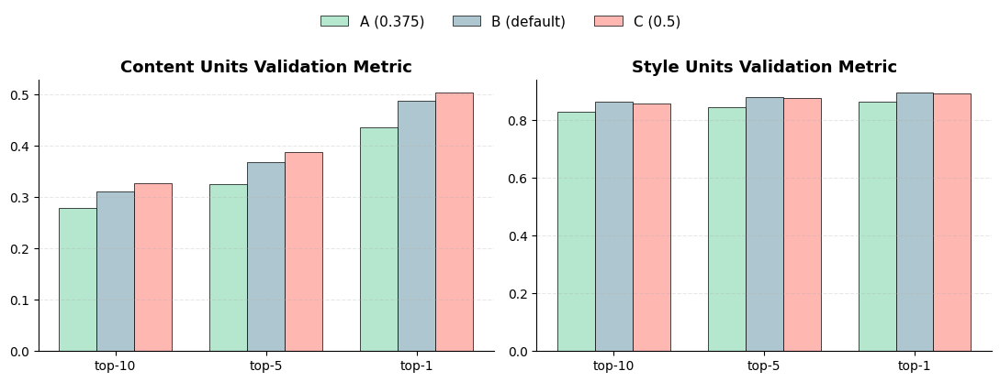

In [11]:
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

# ----- Load data -----
A_content_units_metric = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/0.375_0.375/{model_name}/invertible_content_units_metric.npy')
A_style_units_metric   = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/0.375_0.375/{model_name}/invertible_style_units_metric.npy')

B_content_units_metric = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/{model_name}/invertible_content_units_metric.npy')
B_style_units_metric   = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/{model_name}/invertible_style_units_metric.npy')

C_content_units_metric = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/{model_name}/invertible_content_units_metric.npy')
C_style_units_metric   = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/0.5_0.5/{model_name}/invertible_style_units_metric.npy')

# ----- Labels -----
labels = ['top-10', 'top-5', 'top-1']
x = np.arange(len(labels))
width = 0.25

labels_ABC = ['A (0.375)', 'B (default)', 'C (0.5)']

# Pastel colors
pastel_green = '#B4E7CE'   # A
pastel_blue  = '#AEC6CF'   # B
pastel_pink  = '#FFB7B2'   # C

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)

# ---------- Content Units ----------
axes[0].bar(x - width, A_content_units_metric, width,
            label=labels_ABC[0], color=pastel_green, edgecolor='black', linewidth=0.5)

axes[0].bar(x, B_content_units_metric, width,
            label=labels_ABC[1], color=pastel_blue, edgecolor='black', linewidth=0.5)

axes[0].bar(x + width, C_content_units_metric, width,
            label=labels_ABC[2], color=pastel_pink, edgecolor='black', linewidth=0.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=10)
axes[0].set_title('Content Units Validation Metric', fontsize=13, weight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# ---------- Style Units ----------
axes[1].bar(x - width, A_style_units_metric, width,
            color=pastel_green, edgecolor='black', linewidth=0.5)

axes[1].bar(x, B_style_units_metric, width,
            color=pastel_blue, edgecolor='black', linewidth=0.5)

axes[1].bar(x + width, C_style_units_metric, width,
            color=pastel_pink, edgecolor='black', linewidth=0.5)

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_title('Style Units Validation Metric', fontsize=13, weight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

# ---------- Common Legend ----------
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 1.05), fontsize=11)

# ---------- Clean look ----------
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Results 1 - Invertible, Orthogonal Comp

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

# orthogonal_dir = "inference_outputs/mscoco_retrieval_results/orthogonal/" + model_name + "/0.4375_0.4375/"

# topks = [10, 5, 1]
# unit_types = ["style", "content"]

# # ---------- Load data ----------
# def load_data(acc_type):
#     data = {u: [] for u in unit_types}
#     for unit in unit_types:
#         for k in topks:
#             fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
#             fpath = os.path.join(orthogonal_dir, fname)
#             val = np.load(fpath, allow_pickle=True).item()
#             data[unit].append(val)
#     return data

# orthogonal_content_data = load_data("content")
# orthogonal_content_units_metric = [(c - s) / c for c, s in zip(orthogonal_content_data['content'], orthogonal_content_data['style'])]

# orthogonal_style_data   = load_data("style")
# orthogonal_style_units_metric = [(s-c) / s for c, s in zip(orthogonal_style_data['content'], orthogonal_style_data['style'])]

# np.save('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/0.4375_0.4375/orthogonal_content_units_metric.npy', orthogonal_content_units_metric)
# np.save('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/0.4375_0.4375/orthogonal_style_units_metric.npy', orthogonal_style_units_metric)

invertible_dir = "inference_outputs/mscoco_retrieval_results/invertible/" + model_name + "/0.4375_0.4375/"

topks = [10, 5, 1]
unit_types = ["style", "content"]

# ---------- Load data ----------
def load_data(acc_type):
    data = {u: [] for u in unit_types}
    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(invertible_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)
    return data

invertible_content_data = load_data("content")
invertible_content_units_metric = [(c - s) / c for c, s in zip(invertible_content_data['content'], invertible_content_data['style'])]

invertible_style_data   = load_data("style")
invertible_style_units_metric = [(s-c) / s for c, s in zip(invertible_style_data['content'], invertible_style_data['style'])]

np.save('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/0.4375_0.4375/invertible_content_units_metric.npy', invertible_content_units_metric)
np.save('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/0.4375_0.4375/invertible_style_units_metric.npy', invertible_style_units_metric)

# permutation_dir = "inference_outputs/mscoco_retrieval_results/permutation/" + model_name + "/0.4375_0.4375/"

# topks = [10, 5, 1]
# unit_types = ["style", "content"]

# # ---------- Load data ----------
# def load_data(acc_type):
#     data = {u: [] for u in unit_types}
#     for unit in unit_types:
#         for k in topks:
#             fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
#             fpath = os.path.join(permutation_dir, fname)
#             val = np.load(fpath, allow_pickle=True).item()
#             data[unit].append(val)
#     return data

# permutation_content_data = load_data("content")
# permutation_content_units_metric = [(c - s) / c for c, s in zip(permutation_content_data['content'], permutation_content_data['style'])]

# permutation_style_data   = load_data("style")
# permutation_style_units_metric = [(s-c) / s for c, s in zip(permutation_style_data['content'], permutation_style_data['style'])]

# np.save('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/0.4375_0.4375/permutation_content_units_metric.npy', permutation_content_units_metric)
# np.save('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/0.4375_0.4375/permutation_style_units_metric.npy', permutation_style_units_metric)

In [5]:
invertible_style_units_metric, invertible_content_units_metric

([0.7861771058315334, 0.7848120764017253, 0.798323871316572],
 [0.17808365343576615, 0.21733000759136756, 0.3088201864060014])

In [1]:
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

permutation_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/permutation_content_units_metric.npy')
permutation_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/permutation_style_units_metric.npy')

vals = list(permutation_content_units_metric) + list(permutation_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Permutation & {formatted} & 0.0 & 0.0")

orthogonal_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/orthogonal_content_units_metric.npy')
orthogonal_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/orthogonal_style_units_metric.npy')

vals = list(orthogonal_content_units_metric) + list(orthogonal_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Orthogonal & {formatted} &  0.0 & 0.0")

invertible_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/invertible_content_units_metric.npy')
invertible_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/invertible_style_units_metric.npy')

vals = list(invertible_content_units_metric) + list(invertible_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Invertible & {formatted} &  0.0 & 0.0")




Permutation & 0.0063 & 0.0080 & 0.0125 & 0.0738 & 0.0625 & 0.0546 & 0.0 & 0.0
Orthogonal & 0.1381 & 0.1686 & 0.2435 & 0.7542 & 0.7550 & 0.7613 &  0.0 & 0.0
Invertible & 0.3107 & 0.3675 & 0.4884 & 0.8632 & 0.8785 & 0.8940 &  0.0 & 0.0


In [7]:
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

permutation_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/0.4375_0.4375/permutation_content_units_metric.npy')
permutation_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/0.4375_0.4375/permutation_style_units_metric.npy')

vals = list(permutation_content_units_metric) + list(permutation_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Permutation & {formatted} & 0.0 & 0.0")

orthogonal_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/0.4375_0.4375/orthogonal_content_units_metric.npy')
orthogonal_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/0.4375_0.4375/orthogonal_style_units_metric.npy')

vals = list(orthogonal_content_units_metric) + list(orthogonal_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Orthogonal & {formatted} &  0.0 & 0.0")

invertible_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/0.4375_0.4375/invertible_content_units_metric.npy')
invertible_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/0.4375_0.4375/invertible_style_units_metric.npy')

vals = list(invertible_content_units_metric) + list(invertible_style_units_metric)
formatted = " & ".join(f"{v:.4f}" for v in vals)
print(f"Invertible & {formatted} &  0.0 & 0.0")




Permutation & 0.0007 & 0.0023 & 0.0002 & 0.0096 & 0.0154 & 0.0108 & 0.0 & 0.0
Orthogonal & 0.0034 & -0.0021 & 0.0014 & -0.0024 & -0.0080 & 0.0036 &  0.0 & 0.0
Invertible & 0.0048 & 0.0065 & 0.0042 & 0.0148 & -0.0034 & 0.0165 &  0.0 & 0.0


In [17]:
orthogonal_content_units_metric

array([0.13807042, 0.16864608, 0.24345757])

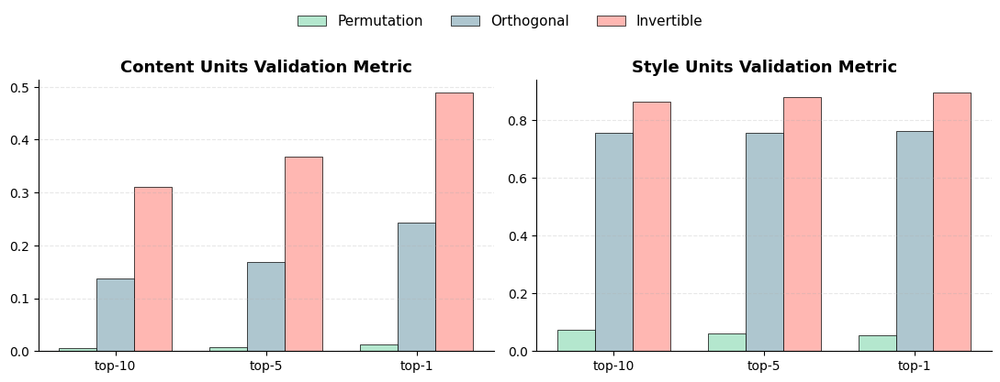

In [3]:
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

orthogonal_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/orthogonal_content_units_metric.npy')
orthogonal_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/orthogonal/' + model_name + '/orthogonal_style_units_metric.npy')

invertible_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/invertible_content_units_metric.npy')
invertible_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/invertible/' + model_name + '/invertible_style_units_metric.npy')

permutation_content_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/permutation_content_units_metric.npy')
permutation_style_units_metric = np.load('inference_outputs/mscoco_retrieval_results/permutation/' + model_name + '/permutation_style_units_metric.npy')

labels = ['top-10', 'top-5', 'top-1']
x = np.arange(len(labels))
width = 0.25

# Pastel palette
pastel_green = '#B4E7CE'   # Permutation
pastel_blue = '#AEC6CF'    # Orthogonal
pastel_pink = '#FFB7B2'    # Invertible

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)

# ---------- Content Units ----------
axes[0].bar(x - width, permutation_content_units_metric, width,
            label='Permutation', color=pastel_green, edgecolor='black', linewidth=0.5)

axes[0].bar(x, orthogonal_content_units_metric, width,
            label='Orthogonal', color=pastel_blue, edgecolor='black', linewidth=0.5)

axes[0].bar(x + width, invertible_content_units_metric, width,
            label='Invertible', color=pastel_pink, edgecolor='black', linewidth=0.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=10)
axes[0].set_title('Content Units Validation Metric', fontsize=13, weight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# ---------- Style Units ----------
axes[1].bar(x - width, permutation_style_units_metric, width,
            color=pastel_green, edgecolor='black', linewidth=0.5)

axes[1].bar(x, orthogonal_style_units_metric, width,
            color=pastel_blue, edgecolor='black', linewidth=0.5)

axes[1].bar(x + width, invertible_style_units_metric, width,
            color=pastel_pink, edgecolor='black', linewidth=0.5)

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_title('Style Units Validation Metric', fontsize=13, weight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

# ---------- Common Legend ----------
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.05), fontsize=11)

# ---------- Global Formatting ----------
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

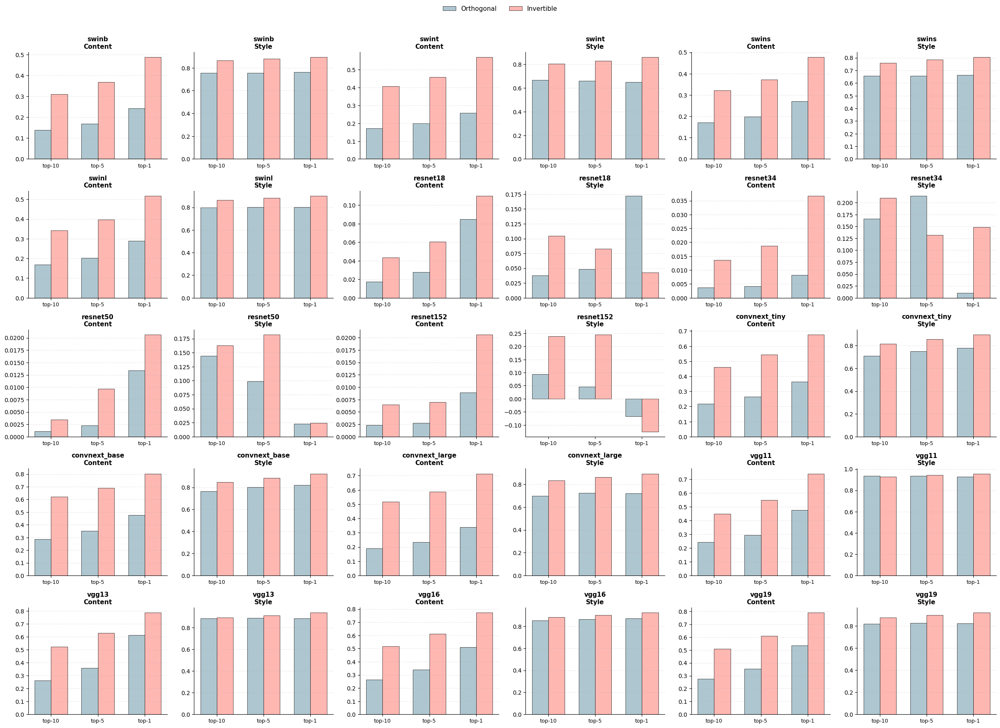

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import math

models = [
    'swinb', 'swint', 'swins', 'swinl',
    'resnet18', 'resnet34', 'resnet50', 'resnet152',
    'convnext_tiny', 'convnext_base', 'convnext_large', 'vgg11', 'vgg13', 'vgg16', 'vgg19'
]

labels = ['top-10', 'top-5', 'top-1']
x = np.arange(len(labels))
width = 0.35

# Pastel palette
pastel_blue = '#AEC6CF'
pastel_pink = '#FFB7B2'

# Layout: 3 models per row → 6 columns (content + style for each)
models_per_row = 3
cols = models_per_row * 2
rows = math.ceil(len(models) / models_per_row)

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))

# Handle edge case when rows=1
if rows == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, model_name in enumerate(models):

    row = idx // models_per_row
    col_block = (idx % models_per_row) * 2

    ax_c = axes[row, col_block]
    ax_s = axes[row, col_block + 1]

    # ---------- Load ----------
    orthogonal_content = np.load(f'inference_outputs/mscoco_retrieval_results/orthogonal/{model_name}/orthogonal_content_units_metric.npy')
    orthogonal_style = np.load(f'inference_outputs/mscoco_retrieval_results/orthogonal/{model_name}/orthogonal_style_units_metric.npy')

    invertible_content = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/{model_name}/invertible_content_units_metric.npy')
    invertible_style = np.load(f'inference_outputs/mscoco_retrieval_results/invertible/{model_name}/invertible_style_units_metric.npy')

    # ---------- Content ----------
    ax_c.bar(x - width/2, orthogonal_content, width,
             color=pastel_blue, edgecolor='black', linewidth=0.5)
    ax_c.bar(x + width/2, invertible_content, width,
             color=pastel_pink, edgecolor='black', linewidth=0.5)

    ax_c.set_xticks(x)
    ax_c.set_xticklabels(labels, fontsize=9)
    ax_c.set_title(f'{model_name}\nContent', fontsize=11, weight='bold')
    ax_c.grid(axis='y', linestyle='--', alpha=0.3)

    # ---------- Style ----------
    ax_s.bar(x - width/2, orthogonal_style, width,
             color=pastel_blue, edgecolor='black', linewidth=0.5, label='Orthogonal')
    ax_s.bar(x + width/2, invertible_style, width,
             color=pastel_pink, edgecolor='black', linewidth=0.5, label='Invertible')

    ax_s.set_xticks(x)
    ax_s.set_xticklabels(labels, fontsize=9)
    ax_s.set_title(f'{model_name}\nStyle', fontsize=11, weight='bold')
    ax_s.grid(axis='y', linestyle='--', alpha=0.3)

    # Clean spines
    for ax in [ax_c, ax_s]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

# Remove empty subplots (if models not divisible by 3)
total_slots = rows * models_per_row
for empty_idx in range(len(models), total_slots):
    row = empty_idx // models_per_row
    col_block = (empty_idx % models_per_row) * 2
    fig.delaxes(axes[row, col_block])
    fig.delaxes(axes[row, col_block + 1])

# Global legend (only once)
handles, labels_legend = ax_s.get_legend_handles_labels()
fig.legend(handles, labels_legend, loc='upper center', ncol=2, frameon=False, fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Results 3e - Geirhos Silhouttes to Edges

In [7]:
from utils.inference_dataloaders import *
from torchvision.models import *
import torch.nn as nn
from utils.models_util import *

params = {'batch_size': 1,
          'shuffle': True,
          'num_workers': 0}

edge_set = Geirhos_Edges()
egde_generator = torch.utils.data.DataLoader(edge_set,  **params)

silhoutte_set = Geirhos_Filled_Silhoutte()
silhoutte_generator = torch.utils.data.DataLoader(silhoutte_set,  **params)

model_name = 'swins'

model = Disentangled_Invertible_Visual_Model(model_name, 'invertible', None).cuda()
model.load_state_dict(torch.load('vision_outputs/invertible/mscoco_stylized_shape_texture_'+model_name+'_0.01_None_avg_invertible_0.4375_0.4375/last_best_model.pt'))

from tqdm import tqdm

content_reps_edges = []
style_reps_edges = []
res_reps_edges = []
content_labels_edges = []

content_reps_silhouttes = []
style_reps_silhouttes = []
res_reps_silhouttes = []
content_labels_silhouttes = []

for X, _, content_label in tqdm(egde_generator):
    with torch.no_grad():
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
                output,
                [
                    int(0.4375 * model.hidden_dim),
                    int(0.4375 * model.hidden_dim),
                    int(0.125  * model.hidden_dim),
                ],
                dim=1,
            )
        content_reps_edges.append(content_rep.cpu().detach().numpy())
        style_reps_edges.append(style_rep.cpu().detach().numpy())
        res_reps_edges.append(res_rep.cpu().detach().numpy())
        content_labels_edges.append(list(content_label))

content_reps_edges = np.array(content_reps_edges)
style_reps_edges = np.array(style_reps_edges)
res_reps_edges = np.array(res_reps_edges)
content_labels_edges = np.array(content_labels_edges)

content_reps_edges = np.squeeze(content_reps_edges)
style_reps_edges = np.squeeze(style_reps_edges)
res_reps_edges = np.squeeze(res_reps_edges)
content_labels_edges = np.squeeze(content_labels_edges)


for X, _, content_label in tqdm(silhoutte_generator):
    with torch.no_grad():
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
                output,
                [
                    int(0.4375 * model.hidden_dim),
                    int(0.4375 * model.hidden_dim),
                    int(0.125  * model.hidden_dim),
                ],
                dim=1,
            )
        content_reps_silhouttes.append(content_rep.cpu().detach().numpy())
        style_reps_silhouttes.append(style_rep.cpu().detach().numpy())
        res_reps_silhouttes.append(res_rep.cpu().detach().numpy())
        content_labels_silhouttes.append(list(content_label))

content_reps_silhouttes = np.array(content_reps_silhouttes)
style_reps_silhouttes = np.array(style_reps_silhouttes)
res_reps_silhouttes = np.array(res_reps_silhouttes)
content_labels_silhouttes = np.array(content_labels_silhouttes)

content_reps_silhouttes = np.squeeze(content_reps_silhouttes)
style_reps_silhouttes = np.squeeze(style_reps_silhouttes)
res_reps_silhouttes = np.squeeze(res_reps_silhouttes)
content_labels_silhouttes = np.squeeze(content_labels_silhouttes)


def nearest_neighbor(A, B):
    diff = np.array([((a - B)**2).mean(axis=1) for a in A])
    idx  = np.argmin(diff, axis=1)
    sorted_indices = np.argsort(diff, axis=1)
    return sorted_indices

sorted_indices = nearest_neighbor(content_reps_silhouttes, content_reps_edges)
top1_preds_edges_silhouttes_content = content_labels_edges[sorted_indices]

sorted_indices = nearest_neighbor(style_reps_silhouttes, style_reps_edges)
top1_preds_edges_silhouttes_style = content_labels_edges[sorted_indices]

sorted_indices = nearest_neighbor(res_reps_silhouttes, res_reps_edges)
top1_preds_edges_silhouttes_res = content_labels_edges[sorted_indices]


content_acc_1, content_acc_5, content_acc_10, style_acc_1, style_acc_5,style_acc_10 = 0.0, 0.0,0.0,0.0,0.0,0.0
res_acc_1, res_acc_5, res_acc_10 = 0.0,0.0,0.0

for content_pred, style_pred, res_pred, true in zip(top1_preds_edges_silhouttes_content, top1_preds_edges_silhouttes_style, top1_preds_edges_silhouttes_res, content_labels_silhouttes):
    if str(true) in content_pred[:1]:
        content_acc_1+= 1
    if str(true) in style_pred[:1]:
        style_acc_1+= 1
    if str(true) in res_pred[:1]:
        res_acc_1+= 1
    if str(true) in content_pred[:10]:
        content_acc_10+= 1
    if str(true) in style_pred[:10]:
        style_acc_10+= 1
    if str(true) in res_pred[:10]:
        res_acc_10+= 1
    if str(true) in content_pred[:5]:
        content_acc_5+= 1
    if str(true) in style_pred[:5]:
        style_acc_5+= 1
    if str(true) in res_pred[:5]:
        res_acc_5+= 1

content_acc_1 = content_acc_1/160
style_acc_1 = style_acc_1/160
res_acc_1 = res_acc_1/160
content_acc_10 = content_acc_10/160
style_acc_10 = style_acc_10/160
res_acc_10 = res_acc_10/160
content_acc_5 = content_acc_5/160
style_acc_5 = style_acc_5/160
res_acc_5 = res_acc_5/160


out_dir = f"inference_outputs/geirhos_silhoutte_edge_exact_cat/{model_name}/"
os.makedirs(out_dir, exist_ok=True)

np.save(os.path.join(out_dir, "content_acc_1.npy"), content_acc_1)
np.save(os.path.join(out_dir, "style_acc_1.npy"), style_acc_1)
np.save(os.path.join(out_dir, "res_acc_1.npy"), res_acc_1)

np.save(os.path.join(out_dir, "content_acc_5.npy"), content_acc_5)
np.save(os.path.join(out_dir, "style_acc_5.npy"), style_acc_5)
np.save(os.path.join(out_dir, "res_acc_5.npy"), res_acc_5)

np.save(os.path.join(out_dir, "content_acc_10.npy"), content_acc_10)
np.save(os.path.join(out_dir, "style_acc_10.npy"), style_acc_10)
np.save(os.path.join(out_dir, "res_acc_10.npy"), res_acc_10)

Using invertible transformation


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 160/160 [00:01<00:00, 92.26it/s]


In [2]:
from utils.inference_dataloaders import *
from torchvision.models import *
import torch.nn as nn
from utils.models_util import *

params = {'batch_size': 1,
          'shuffle': True,
          'num_workers': 0}

edge_set = Geirhos_Edges()
egde_generator = torch.utils.data.DataLoader(edge_set,  **params)

silhoutte_set = Geirhos_Filled_Silhoutte()
silhoutte_generator = torch.utils.data.DataLoader(silhoutte_set,  **params)

model_name = 'swinb'

model = Disentangled_Invertible_Visual_Model(model_name, 'invertible', None).cuda()
model.load_state_dict(torch.load('vision_outputs/invertible/mscoco_stylized_shape_texture_'+model_name+'_0.01_None_avg_invertible_0.4375_0.4375/last_best_model.pt'))

from tqdm import tqdm

content_reps_edges = []
style_reps_edges = []
res_reps_edges = []
content_labels_edges = []

content_reps_silhouttes = []
style_reps_silhouttes = []
res_reps_silhouttes = []
content_labels_silhouttes = []

for X, content_label, _ in tqdm(egde_generator):
    with torch.no_grad():
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
                output,
                [
                    int(0.4375 * model.hidden_dim),
                    int(0.4375 * model.hidden_dim),
                    int(0.125  * model.hidden_dim),
                ],
                dim=1,
            )
        content_reps_edges.append(content_rep.cpu().detach().numpy())
        style_reps_edges.append(style_rep.cpu().detach().numpy())
        res_reps_edges.append(res_rep.cpu().detach().numpy())
        content_labels_edges.append(list(content_label))

content_reps_edges = np.array(content_reps_edges)
style_reps_edges = np.array(style_reps_edges)
res_reps_edges = np.array(res_reps_edges)
content_labels_edges = np.array(content_labels_edges)

content_reps_edges = np.squeeze(content_reps_edges)
style_reps_edges = np.squeeze(style_reps_edges)
res_reps_edges = np.squeeze(res_reps_edges)
content_labels_edges = np.squeeze(content_labels_edges)


for X, content_label, _ in tqdm(silhoutte_generator):
    with torch.no_grad():
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
                output,
                [
                    int(0.4375 * model.hidden_dim),
                    int(0.4375 * model.hidden_dim),
                    int(0.125  * model.hidden_dim),
                ],
                dim=1,
            )
        content_reps_silhouttes.append(content_rep.cpu().detach().numpy())
        style_reps_silhouttes.append(style_rep.cpu().detach().numpy())
        res_reps_silhouttes.append(res_rep.cpu().detach().numpy())
        content_labels_silhouttes.append(list(content_label))

content_reps_silhouttes = np.array(content_reps_silhouttes)
style_reps_silhouttes = np.array(style_reps_silhouttes)
res_reps_silhouttes = np.array(res_reps_silhouttes)
content_labels_silhouttes = np.array(content_labels_silhouttes)

content_reps_silhouttes = np.squeeze(content_reps_silhouttes)
style_reps_silhouttes = np.squeeze(style_reps_silhouttes)
res_reps_silhouttes = np.squeeze(res_reps_silhouttes)
content_labels_silhouttes = np.squeeze(content_labels_silhouttes)


def nearest_neighbor(A, B):
    diff = np.array([((a - B)**2).mean(axis=1) for a in A])
    idx  = np.argmin(diff, axis=1)
    sorted_indices = np.argsort(diff, axis=1)
    return sorted_indices

sorted_indices = nearest_neighbor(content_reps_silhouttes, content_reps_edges)
top1_preds_edges_silhouttes_content = content_labels_edges[sorted_indices]

sorted_indices = nearest_neighbor(style_reps_silhouttes, style_reps_edges)
top1_preds_edges_silhouttes_style = content_labels_edges[sorted_indices]

sorted_indices = nearest_neighbor(res_reps_silhouttes, res_reps_edges)
top1_preds_edges_silhouttes_res = content_labels_edges[sorted_indices]


content_acc_1, content_acc_5, content_acc_10, style_acc_1, style_acc_5,style_acc_10 = 0.0, 0.0,0.0,0.0,0.0,0.0
res_acc_1, res_acc_5, res_acc_10 = 0.0,0.0,0.0

for content_pred, style_pred, res_pred, true in zip(top1_preds_edges_silhouttes_content, top1_preds_edges_silhouttes_style, top1_preds_edges_silhouttes_res, content_labels_silhouttes):
    if str(true) in content_pred[:1]:
        content_acc_1+= 1
    if str(true) in style_pred[:1]:
        style_acc_1+= 1
    if str(true) in res_pred[:1]:
        res_acc_1+= 1
    if str(true) in content_pred[:10]:
        content_acc_10+= 1
    if str(true) in style_pred[:10]:
        style_acc_10+= 1
    if str(true) in res_pred[:10]:
        res_acc_10+= 1
    if str(true) in content_pred[:5]:
        content_acc_5+= 1
    if str(true) in style_pred[:5]:
        style_acc_5+= 1
    if str(true) in res_pred[:5]:
        res_acc_5+= 1

content_acc_1 = content_acc_1/160
style_acc_1 = style_acc_1/160
res_acc_1 = res_acc_1/160
content_acc_10 = content_acc_10/160
style_acc_10 = style_acc_10/160
res_acc_10 = res_acc_10/160
content_acc_5 = content_acc_5/160
style_acc_5 = style_acc_5/160
res_acc_5 = res_acc_5/160


out_dir = f"inference_outputs/geirhos_silhoutte_edge/{model_name}/"
os.makedirs(out_dir, exist_ok=True)

np.save(os.path.join(out_dir, "content_acc_1.npy"), content_acc_1)
np.save(os.path.join(out_dir, "style_acc_1.npy"), style_acc_1)
np.save(os.path.join(out_dir, "res_acc_1.npy"), res_acc_1)

np.save(os.path.join(out_dir, "content_acc_5.npy"), content_acc_5)
np.save(os.path.join(out_dir, "style_acc_5.npy"), style_acc_5)
np.save(os.path.join(out_dir, "res_acc_5.npy"), res_acc_5)

np.save(os.path.join(out_dir, "content_acc_10.npy"), content_acc_10)
np.save(os.path.join(out_dir, "style_acc_10.npy"), style_acc_10)
np.save(os.path.join(out_dir, "res_acc_10.npy"), res_acc_10)

Using invertible transformation


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 160/160 [00:01<00:00, 86.61it/s]


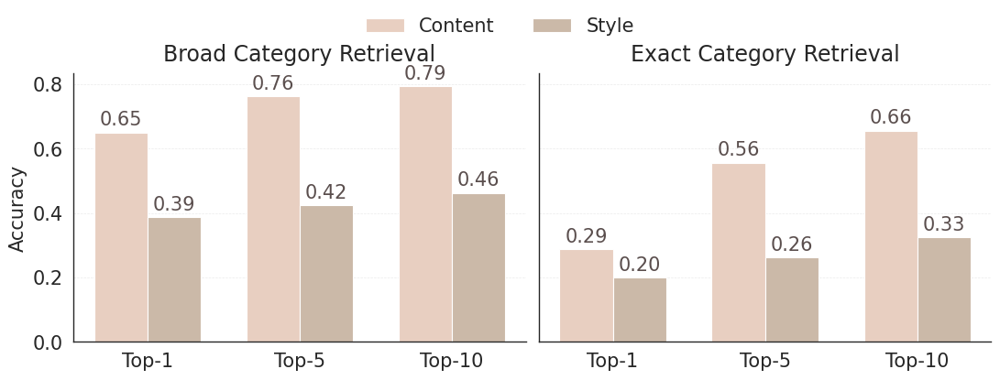

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import os

model_name = 'swinb'

# ---------- Load Broad ----------
out_dir1 = f"inference_outputs/geirhos_silhoutte_edge/{model_name}/"

content1 = [
    np.load(os.path.join(out_dir1, "content_acc_1.npy")),
    np.load(os.path.join(out_dir1, "content_acc_5.npy")),
    np.load(os.path.join(out_dir1, "content_acc_10.npy"))
]
style1 = [
    np.load(os.path.join(out_dir1, "style_acc_1.npy")),
    np.load(os.path.join(out_dir1, "style_acc_5.npy")),
    np.load(os.path.join(out_dir1, "style_acc_10.npy"))
]

# ---------- Load Exact ----------
out_dir2 = f"inference_outputs/geirhos_silhoutte_edge_exact_cat/{model_name}/"

content2 = [
    np.load(os.path.join(out_dir2, "content_acc_1.npy")),
    np.load(os.path.join(out_dir2, "content_acc_5.npy")),
    np.load(os.path.join(out_dir2, "content_acc_10.npy"))
]
style2 = [
    np.load(os.path.join(out_dir2, "style_acc_1.npy")),
    np.load(os.path.join(out_dir2, "style_acc_5.npy")),
    np.load(os.path.join(out_dir2, "style_acc_10.npy"))
]

# ---------- Common setup ----------
labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.35

content_color = '#E8CFC1'
style_color   = '#CBB9A8'

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

def make_plot(ax, content, style, title):
    bars1 = ax.bar(x - width/2, content, width, label='Content', color=content_color)
    bars2 = ax.bar(x + width/2, style,   width, label='Style',   color=style_color)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=15)
    ax.set_title(title, fontsize=17, pad=10)

    # Increase y-tick fontsize
    ax.tick_params(axis='y', labelsize=15)

    # styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
    ax.set_axisbelow(True)

    # annotations
    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                h + 0.01,
                f"{h:.2f}",
                ha='center',
                va='bottom',
                fontsize=15,
                color='#5A4E4D'
            )

# ---------- Plot ----------
make_plot(axes[0], content1, style1, "Broad Category Retrieval")
make_plot(axes[1], content2, style2, "Exact Category Retrieval")

axes[0].set_ylabel('Accuracy', fontsize=15)

# single legend (cleaner)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', ncol=2, frameon=False, fontsize=15)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('neurips_2026_images/geirhos_silhoutte_edge.pdf')
plt.show()

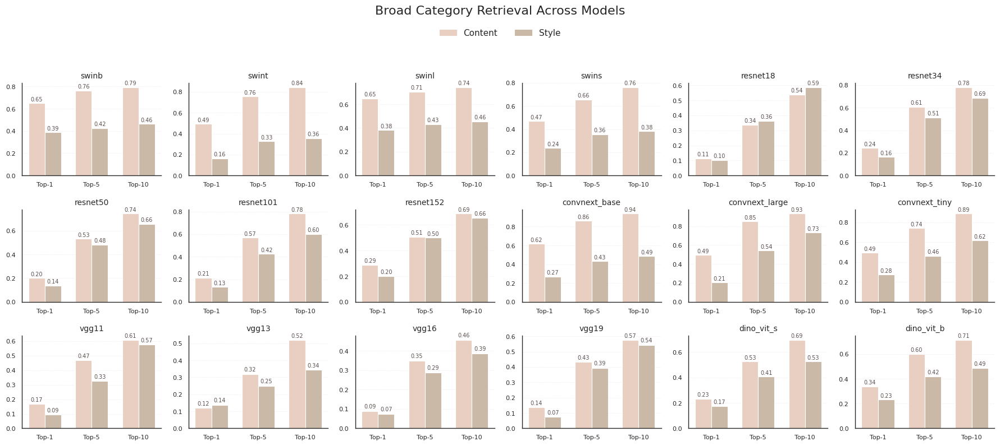

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.35

content_color = '#E8CFC1'
style_color   = '#CBB9A8'

ncols = 6
nrows = int(np.ceil(len(model_names) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 8))
axes = axes.flatten()

def annotate(ax, bars):
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h:.2f}",
            ha='center',
            va='bottom',
            fontsize=7,
            color='#5A4E4D'
        )

for i, model_name in enumerate(model_names):
    ax = axes[i]
    out_dir = f"inference_outputs/geirhos_silhoutte_edge/{model_name}/"

    try:
        content = [
            np.load(os.path.join(out_dir, "content_acc_1.npy")),
            np.load(os.path.join(out_dir, "content_acc_5.npy")),
            np.load(os.path.join(out_dir, "content_acc_10.npy"))
        ]

        style = [
            np.load(os.path.join(out_dir, "style_acc_1.npy")),
            np.load(os.path.join(out_dir, "style_acc_5.npy")),
            np.load(os.path.join(out_dir, "style_acc_10.npy"))
        ]

        bars1 = ax.bar(x - width/2, content, width, color=content_color)
        bars2 = ax.bar(x + width/2, style,   width, color=style_color)

        annotate(ax, bars1)
        annotate(ax, bars2)

    except FileNotFoundError:
        ax.text(0.5, 0.5, "Missing", ha='center', va='center', fontsize=9)

    ax.set_title(model_name, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.tick_params(axis='y', labelsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)

# Remove unused axes
for j in range(len(model_names), len(axes)):
    fig.delaxes(axes[j])

# Legend (move slightly DOWN from top)
handles = [
    plt.Rectangle((0,0),1,1,color=content_color),
    plt.Rectangle((0,0),1,1,color=style_color)
]
fig.legend(handles, ['Content', 'Style'],
           loc='upper center',
           bbox_to_anchor=(0.5, 0.96),  # key fix
           ncol=2,
           frameon=False,
           fontsize=11)

# Title (slightly higher)
fig.suptitle('Broad Category Retrieval Across Models',
             fontsize=16, y=0.995)

# Reserve top space for title + legend
plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig('neurips_2026_images/exact_broad_all.pdf')
plt.show()

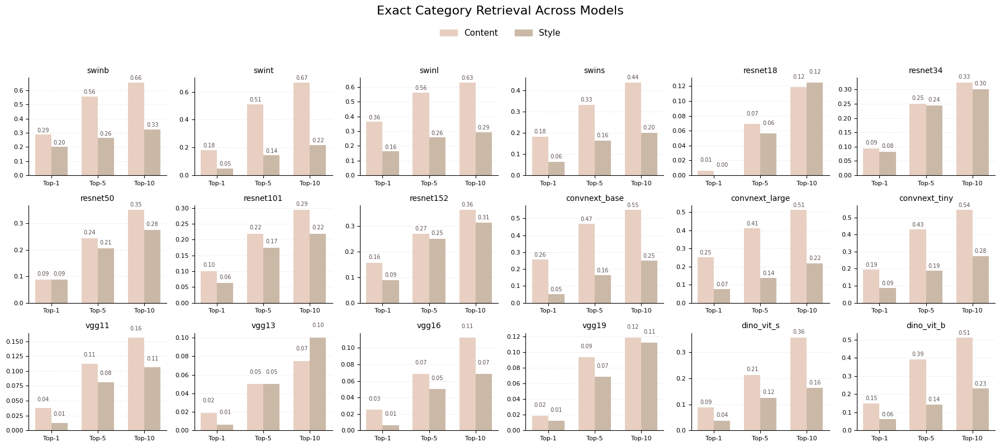

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import os

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

labels = ['Top-1', 'Top-5', 'Top-10']
x = np.arange(len(labels))
width = 0.35

content_color = '#E8CFC1'
style_color   = '#CBB9A8'

ncols = 6
nrows = int(np.ceil(len(model_names) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 8))
axes = axes.flatten()

def annotate(ax, bars):
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.01,
            f"{h:.2f}",
            ha='center',
            va='bottom',
            fontsize=7,
            color='#5A4E4D'
        )

for i, model_name in enumerate(model_names):
    ax = axes[i]
    out_dir = f"inference_outputs/geirhos_silhoutte_edge_exact_cat/{model_name}/"

    try:
        content = [
            np.load(os.path.join(out_dir, "content_acc_1.npy")),
            np.load(os.path.join(out_dir, "content_acc_5.npy")),
            np.load(os.path.join(out_dir, "content_acc_10.npy"))
        ]

        style = [
            np.load(os.path.join(out_dir, "style_acc_1.npy")),
            np.load(os.path.join(out_dir, "style_acc_5.npy")),
            np.load(os.path.join(out_dir, "style_acc_10.npy"))
        ]

        bars1 = ax.bar(x - width/2, content, width, color=content_color)
        bars2 = ax.bar(x + width/2, style,   width, color=style_color)

        annotate(ax, bars1)
        annotate(ax, bars2)

    except FileNotFoundError:
        ax.text(0.5, 0.5, "Missing", ha='center', va='center', fontsize=9)

    ax.set_title(model_name, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.tick_params(axis='y', labelsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)

# Remove unused axes
for j in range(len(model_names), len(axes)):
    fig.delaxes(axes[j])

# Legend (move slightly DOWN from top)
handles = [
    plt.Rectangle((0,0),1,1,color=content_color),
    plt.Rectangle((0,0),1,1,color=style_color)
]
fig.legend(handles, ['Content', 'Style'],
           loc='upper center',
           bbox_to_anchor=(0.5, 0.96),  # key fix
           ncol=2,
           frameon=False,
           fontsize=11)

# Title (slightly higher)
fig.suptitle('Exact Category Retrieval Across Models',
             fontsize=16, y=0.995)

# Reserve top space for title + legend
plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.show()

# Results 3d - Conflicting Cues Retrieval Accuracy

In [20]:
from utils.inference_dataloaders import *
from torchvision.models import *
import torch.nn as nn


params = {'batch_size': 1,
          'shuffle': True,
          'num_workers': 0}

all_set = Geirhos_Conflicting_Cues()
all_generator = torch.utils.data.DataLoader(all_set,  **params)


from utils.models_util import *

model_name = 'dino_vit_b'
model = Disentangled_Invertible_Visual_Model(model_name, 'invertible', None).cuda()
model.load_state_dict(torch.load('vision_outputs/invertible/mscoco_stylized_shape_texture_' + model_name + '_0.01_None_avg_invertible_0.4375_0.4375/last_best_model.pt'))

from tqdm import tqdm

content_reps = []
content_labels = []

style_reps = []
style_labels = []

res_reps = []

org_reps = []

images = []

for X, content_label, style_label in tqdm(all_generator):
    with torch.no_grad():
        images.append(X.numpy())
        output = model(X.cuda())
        content_rep, style_rep, res_rep = torch.split(
                output,
                [
                    int(0.4375 * model.hidden_dim),
                    int(0.4375 * model.hidden_dim),
                    int(0.125  * model.hidden_dim),
                ],
                dim=1,
            )
        content_reps.append(content_rep.cpu().detach().numpy())
        style_reps.append(style_rep.cpu().detach().numpy())
        res_reps.append(res_rep.cpu().detach().numpy())
        content_labels.append(list(content_label))
        style_labels.append(style_label)

content_reps = np.array(content_reps)
style_reps = np.array(style_reps)
content_labels = np.array(content_labels)
style_labels = np.array(style_labels)
res_reps = np.array(res_reps)

content_reps = np.squeeze(content_reps)
style_reps = np.squeeze(style_reps)
res_reps = np.squeeze(res_reps)
content_labels = np.squeeze(content_labels)


def get_nearest_10_neighbors(X, k=10):
    diff = X[:, None, :] - X[None, :, :]     # (N, N, D)
    mse = np.mean(diff**2, axis=-1)          # (N, N))
    neighbors = np.argsort(mse, axis=1)      # (N, N)
    neighbors = neighbors[:, 1:k+1]
    return neighbors

def get_topk_accuracy(neighbors, k):
    top_k_content = 0.0
    top_k_style = 0.0
    pred_content = content_labels[neighbors]
    pred_style = style_labels[neighbors]
    for i in range(len(pred_content)):
        if content_labels[i] in pred_content[i][:k]:
            top_k_content+= 1.0
        if style_labels[i] in pred_style[i][:k]:
            top_k_style+= 1.0
    return top_k_content/len(pred_content), top_k_style/len(pred_content)
    

style_nearest_neighbors = get_nearest_10_neighbors(style_reps)
style_units_content_acc_10, style_units_style_acc_10 = get_topk_accuracy(style_nearest_neighbors, 10)
style_units_content_acc_5, style_units_style_acc_5 = get_topk_accuracy(style_nearest_neighbors, 5)
style_units_content_acc_1, style_units_style_acc_1 = get_topk_accuracy(style_nearest_neighbors, 1)

content_nearest_neighbors = get_nearest_10_neighbors(content_reps)
content_units_content_acc_10, content_units_style_acc_10 = get_topk_accuracy(content_nearest_neighbors, 10)
content_units_content_acc_5, content_units_style_acc_5 = get_topk_accuracy(content_nearest_neighbors, 5)
content_units_content_acc_1, content_units_style_acc_1 = get_topk_accuracy(content_nearest_neighbors, 1)

res_nearest_neighbors = get_nearest_10_neighbors(res_reps)
res_units_content_acc_10, res_units_style_acc_10 = get_topk_accuracy(res_nearest_neighbors, 10)
res_units_content_acc_5, res_units_style_acc_5 = get_topk_accuracy(res_nearest_neighbors, 5)
res_units_content_acc_1, res_units_style_acc_1 = get_topk_accuracy(res_nearest_neighbors, 1)

out_dir = f"inference_outputs/conflicting_cues_retrieval_acc/{model_name}/"
os.makedirs(out_dir, exist_ok=True)

# -------- style --------
np.save(os.path.join(out_dir, "style_units_content_acc_10.npy"), style_units_content_acc_10)
np.save(os.path.join(out_dir, "style_units_style_acc_10.npy"), style_units_style_acc_10)

np.save(os.path.join(out_dir, "style_units_content_acc_5.npy"), style_units_content_acc_5)
np.save(os.path.join(out_dir, "style_units_style_acc_5.npy"), style_units_style_acc_5)

np.save(os.path.join(out_dir, "style_units_content_acc_1.npy"), style_units_content_acc_1)
np.save(os.path.join(out_dir, "style_units_style_acc_1.npy"), style_units_style_acc_1)

# -------- content --------
np.save(os.path.join(out_dir, "content_units_content_acc_10.npy"), content_units_content_acc_10)
np.save(os.path.join(out_dir, "content_units_style_acc_10.npy"), content_units_style_acc_10)

np.save(os.path.join(out_dir, "content_units_content_acc_5.npy"), content_units_content_acc_5)
np.save(os.path.join(out_dir, "content_units_style_acc_5.npy"), content_units_style_acc_5)

np.save(os.path.join(out_dir, "content_units_content_acc_1.npy"), content_units_content_acc_1)
np.save(os.path.join(out_dir, "content_units_style_acc_1.npy"), content_units_style_acc_1)

# -------- res --------
np.save(os.path.join(out_dir, "res_units_content_acc_10.npy"), res_units_content_acc_10)
np.save(os.path.join(out_dir, "res_units_style_acc_10.npy"), res_units_style_acc_10)

np.save(os.path.join(out_dir, "res_units_content_acc_5.npy"), res_units_content_acc_5)
np.save(os.path.join(out_dir, "res_units_style_acc_5.npy"), res_units_style_acc_5)

np.save(os.path.join(out_dir, "res_units_content_acc_1.npy"), res_units_content_acc_1)
np.save(os.path.join(out_dir, "res_units_style_acc_1.npy"), res_units_style_acc_1)

Using invertible transformation


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1280/1280 [00:13<00:00, 92.92it/s]


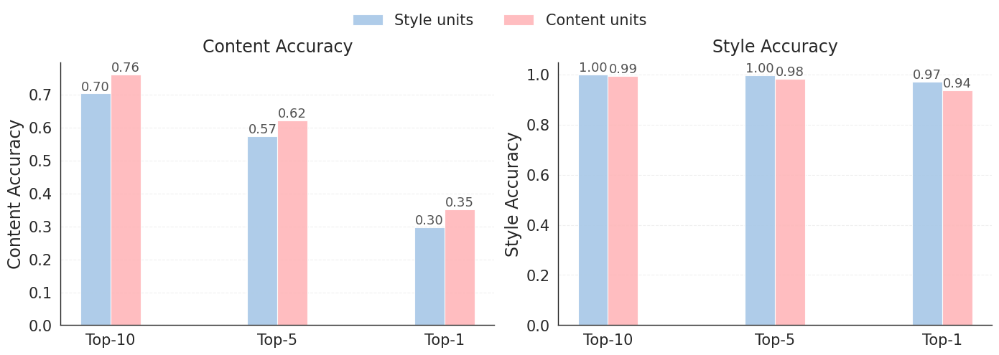

In [42]:
import os
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'
base_dir = "inference_outputs/conflicting_cues_retrieval_acc/" + model_name

topks = [10, 5, 1]
unit_types = ["style", "content"]

# ---------- Load data ----------
def load_data(acc_type):
    data = {u: [] for u in unit_types}
    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)
    return data

content_data = load_data("content")
style_data   = load_data("style")

# ---------- Plot setup ----------
x = np.arange(len(topks))
width = 0.18

colors = {
    "style":   "#A7C7E7",
    "content": "#FFB6B9",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

plots = [
    (axes[0], content_data, "Content Accuracy"),
    (axes[1], style_data, "Style Accuracy")
]

for ax, data, title in plots:

    bars = []
    for i, unit in enumerate(unit_types):
        bars.append(
            ax.bar(
                x + (i - 0.5) * width,
                data[unit],
                width,
                label=f"{unit.capitalize()} units",
                color=colors[unit],
                alpha=0.9
            )
        )

    # axis formatting
    ax.set_xticks(x)
    ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'], fontsize=15)
    ax.set_ylabel(title, fontsize=17)
    ax.set_title(title, fontsize=17, pad=10)

    # Increase y-tick fontsize
    ax.tick_params(axis='y', labelsize=15)

    ax.grid(axis='y', linestyle='--', alpha=0.3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # annotations
    for group in bars:
        for bar in group:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                h,
                f"{h:.2f}",
                ha='center',
                va='bottom',
                fontsize=13,
                alpha=0.8
            )

# shared legend (clean look)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=15)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('neurips_2026_images/geirhos_conflicting_cues.pdf')
plt.show()

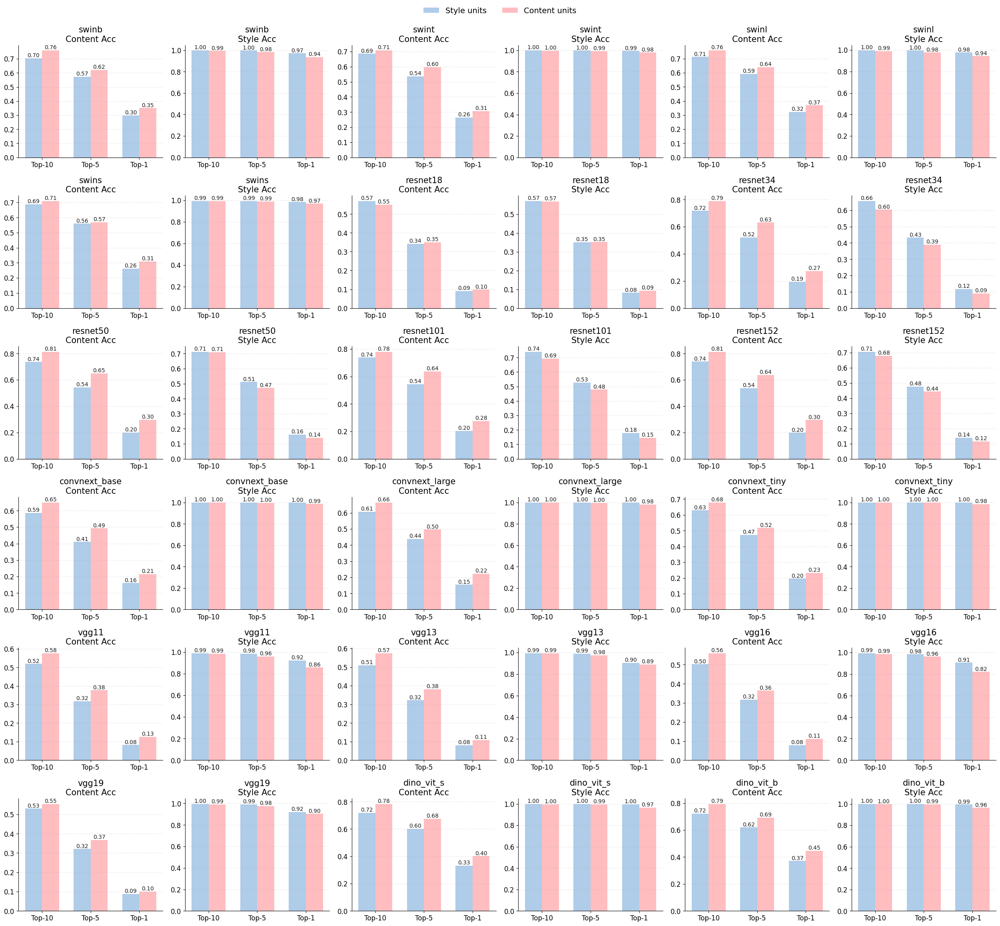

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Patch

# ---------------- GLOBAL FONT SETTINGS ----------------
mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
})

# ---------------- MODELS ----------------
model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

base_dir_template = "inference_outputs/conflicting_cues_retrieval_acc/{model}"
topks = [10, 5, 1]
unit_types = ["style", "content"]

colors = {
    "style": "#A7C7E7",
    "content": "#FFB6B9",
}

# ---------------- LOAD DATA ----------------
def load_data(model_name, acc_type):
    base_dir = base_dir_template.format(model=model_name)
    data = {u: [] for u in unit_types}

    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)

    return data

# ---------------- LAYOUT ----------------
n_models = len(model_names)
n_cols = 6   # 3 model pairs per row (content + style = 2 cols each)
n_rows = 6   # 18 models → 6 rows

fig = plt.figure(figsize=(n_cols * 4.2, n_rows * 3.8))

x = np.arange(len(topks))
width = 0.35

# ---------------- PLOTTING ----------------
for idx, model_name in enumerate(model_names):

    row = idx // 3
    col_pair = idx % 3

    try:
        content_data = load_data(model_name, "content")
        style_data   = load_data(model_name, "style")
    except FileNotFoundError as e:
        print(f"[SKIP] {model_name}: {e}")
        continue

    plots = [
        (content_data, "Content Acc", row * n_cols + col_pair * 2 + 1),
        (style_data,   "Style Acc",   row * n_cols + col_pair * 2 + 2),
    ]

    for data, acc_label, subplot_idx in plots:
        ax = fig.add_subplot(n_rows, n_cols, subplot_idx)

        bars = []
        for i, unit in enumerate(unit_types):
            bars.append(
                ax.bar(
                    x + (i - 0.5) * width,
                    data[unit],
                    width,
                    label=f"{unit.capitalize()} units",
                    color=colors[unit],
                    alpha=0.9
                )
            )

        ax.set_xticks(x)
        ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'])

        ax.set_title(f"{model_name}\n{acc_label}", pad=6)

        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        # value labels (slightly larger for readability)
        for group in bars:
            for bar in group:
                h = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h,
                    f"{h:.2f}",
                    ha='center',
                    va='bottom',
                    fontsize=10,
                    alpha=0.9
                )

# ---------------- LEGEND ----------------
legend_elements = [
    Patch(facecolor=colors["style"], alpha=0.9, label="Style units"),
    Patch(facecolor=colors["content"], alpha=0.9, label="Content units"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
plt.show()

# Results 3c - Top 100 Retrieval on MSCOCO

In [14]:
import numpy as np

transformation = 'permutation'

model_names = [
    'swinb'
]

for model_name in model_names:


    out_dir = f"inference_outputs/mscoco_top100_retrieval_results/{transformation}/{model_name}/"
    Content_units = np.load(out_dir + 'Content_units.npy')
    Style_units = np.load(out_dir + 'Style_units.npy')
    
    ss = Style_units[0]/Content_units[0]
    cs = Content_units[1]/Style_units[1]
    
    print(model_name)
    print(f"{ss:.4f} & {cs:.4f}")

swinb
1.0141 & 1.0011


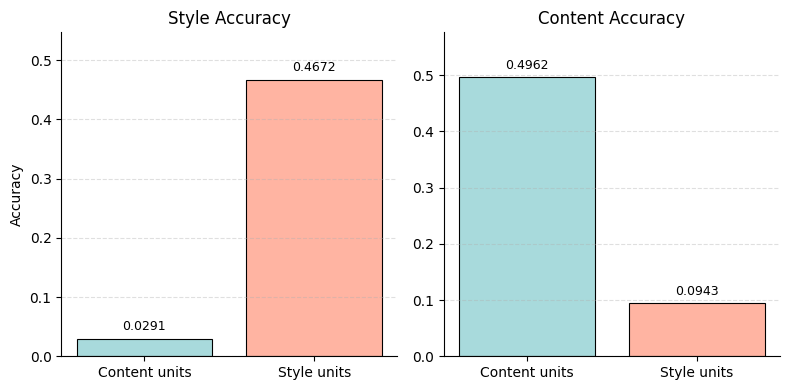

In [2]:
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'

out_dir = f"inference_outputs/mscoco_top100_retrieval_results/invertible/{model_name}/"
Content_units = np.load(out_dir + 'Content_units.npy')
Style_units = np.load(out_dir + 'Style_units.npy')

content_color = '#A8DADC'
style_color = '#FFB4A2'

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# --- Left: Style Accuracy ---
vals_left = [Content_units[0], Style_units[0]]
bars_left = axes[0].bar(['Content units', 'Style units'],
                        vals_left,
                        color=[content_color, style_color],
                        edgecolor='black', linewidth=0.8)

axes[0].set_title('Style Accuracy')
axes[0].set_ylabel('Accuracy')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].set_ylim(0, max(vals_left) + 0.08)

# Add labels
for bar in bars_left:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.01,
                 f"{h:.4f}", ha='center', va='bottom', fontsize=9)

# --- Right: Content Accuracy ---
vals_right = [Content_units[1], Style_units[1]]
bars_right = axes[1].bar(['Content units', 'Style units'],
                         vals_right,
                         color=[content_color, style_color],
                         edgecolor='black', linewidth=0.8)

axes[1].set_title('Content Accuracy')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].set_ylim(0, max(vals_right) + 0.08)

# Add labels
for bar in bars_right:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.01,
                 f"{h:.4f}", ha='center', va='bottom', fontsize=9)

# Clean up
for ax in axes:
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

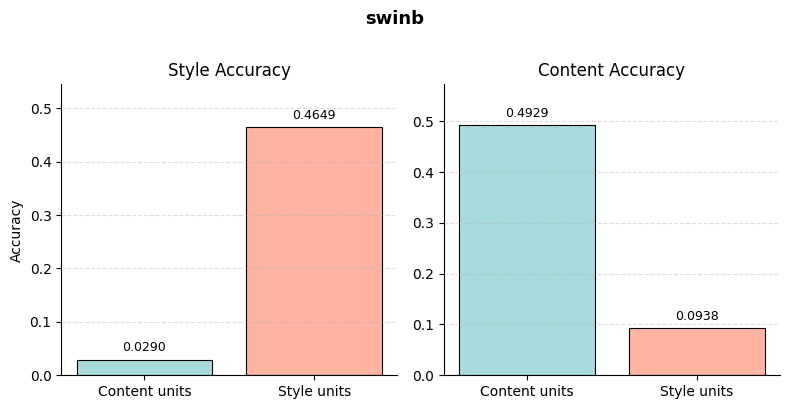

[DONE] swinb


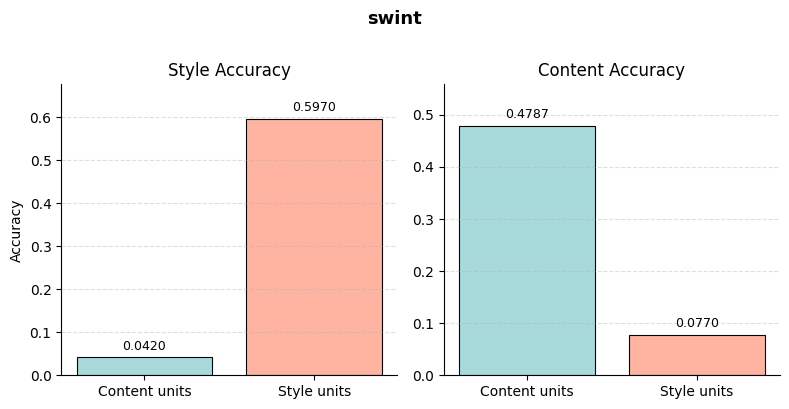

[DONE] swint


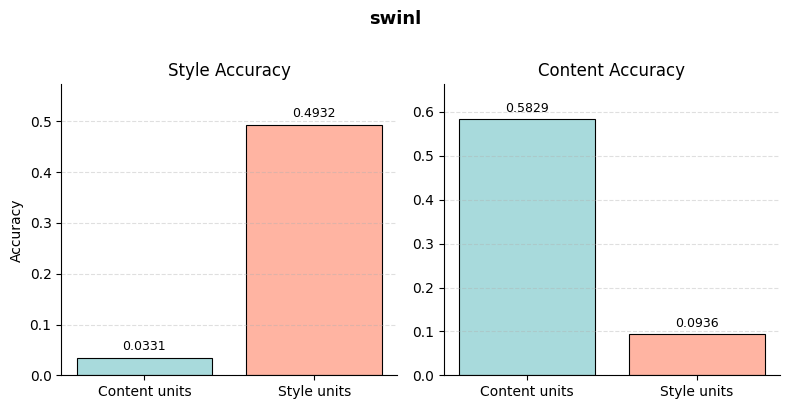

[DONE] swinl


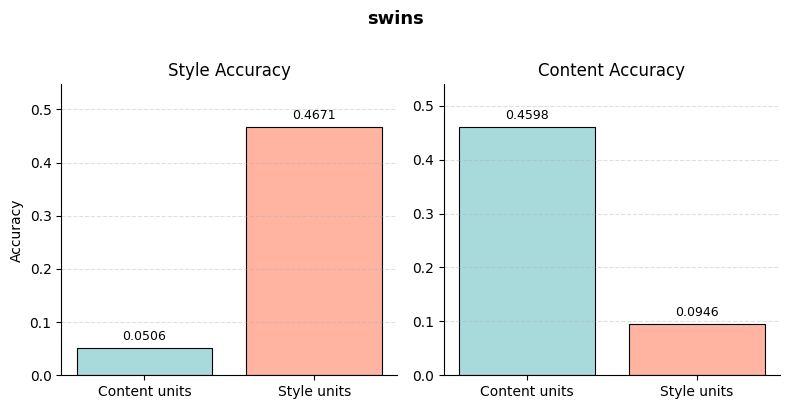

[DONE] swins


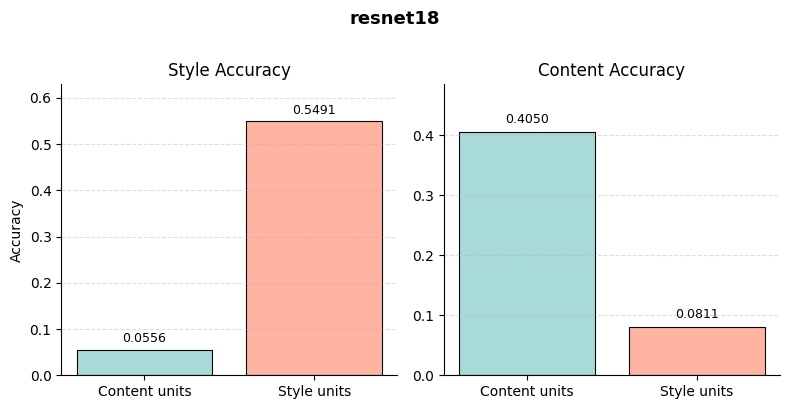

[DONE] resnet18


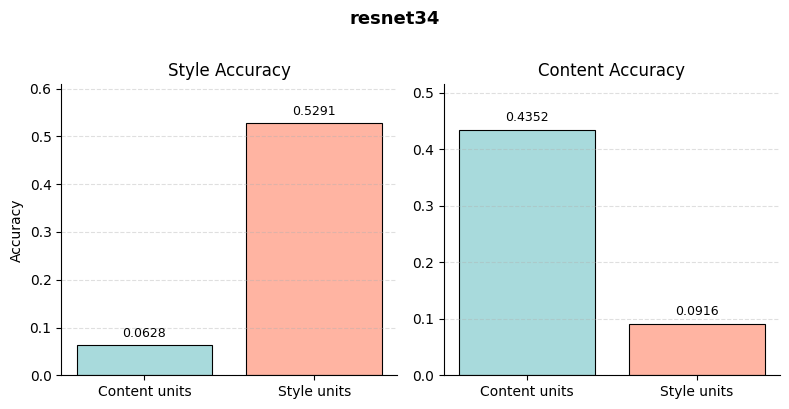

[DONE] resnet34


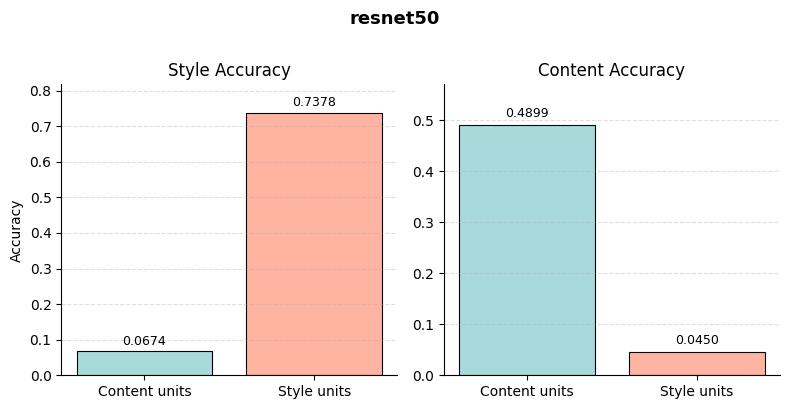

[DONE] resnet50


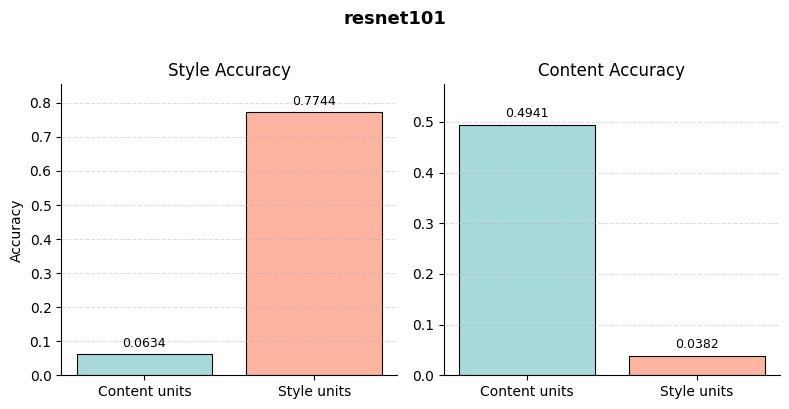

[DONE] resnet101


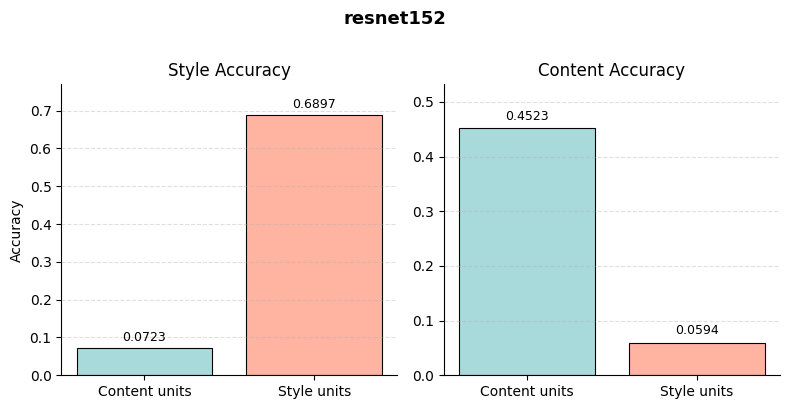

[DONE] resnet152


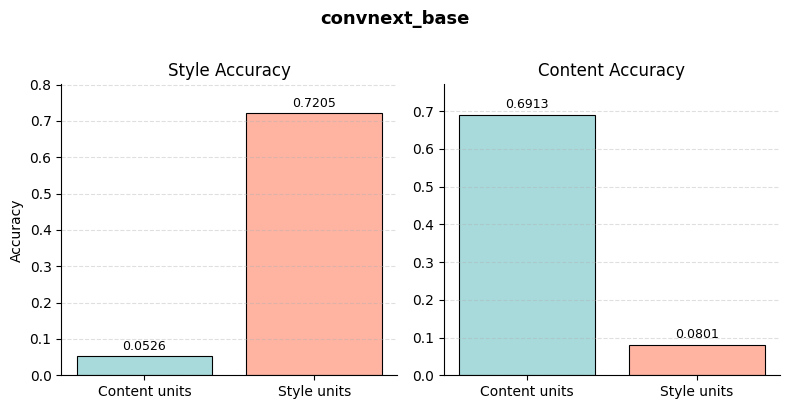

[DONE] convnext_base


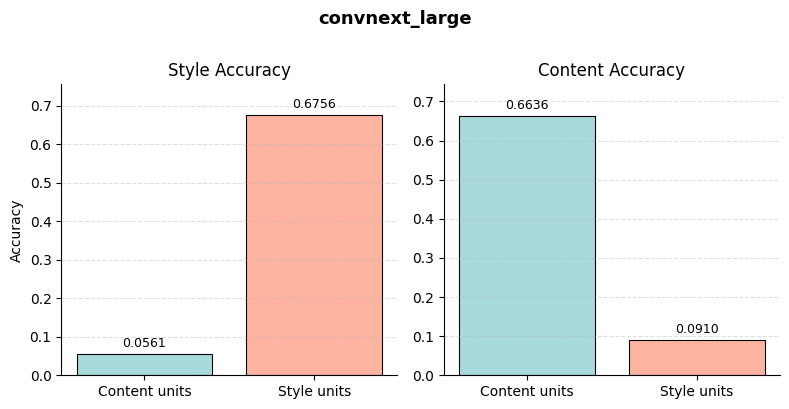

[DONE] convnext_large


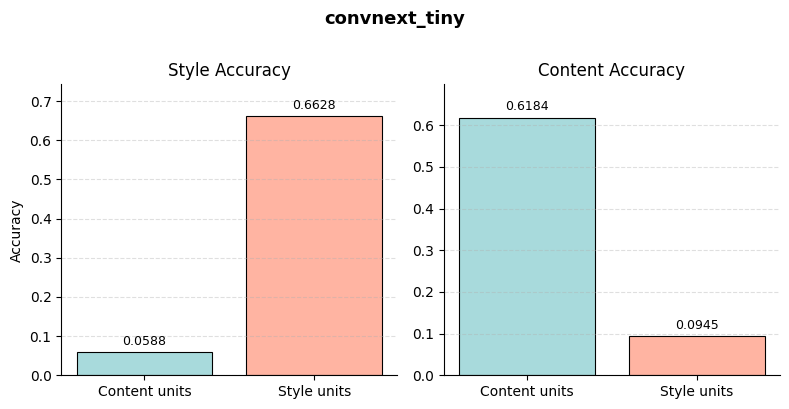

[DONE] convnext_tiny


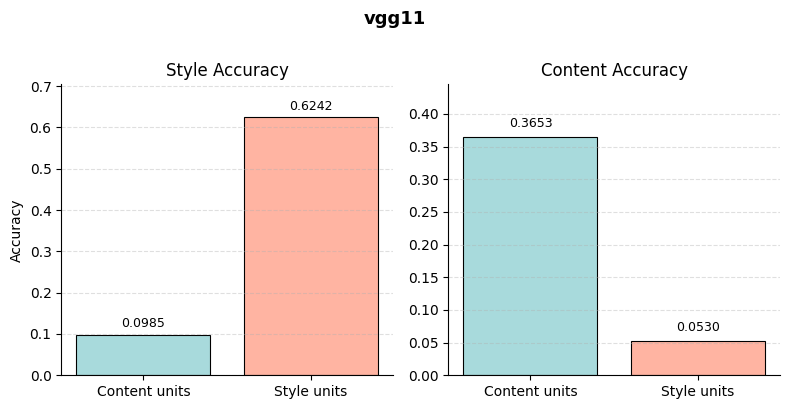

[DONE] vgg11


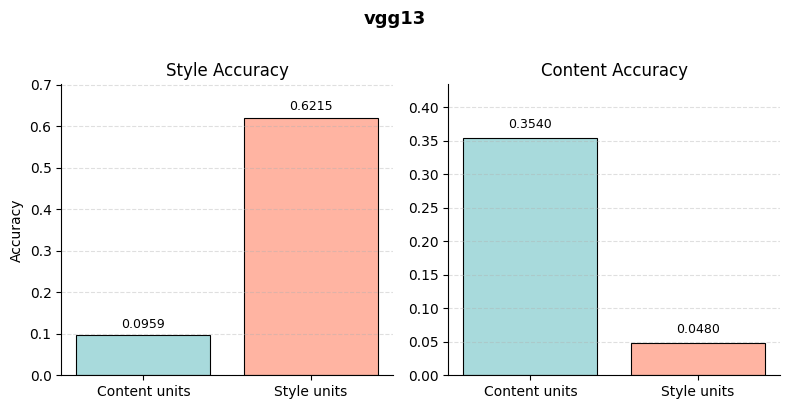

[DONE] vgg13
[SKIP] Missing files for model: vgg16
[SKIP] Missing files for model: vgg19


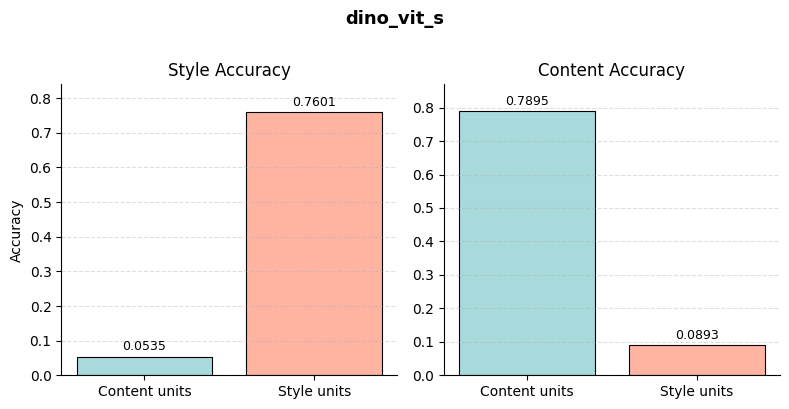

[DONE] dino_vit_s
[SKIP] Missing files for model: dino_vit_b


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

content_color = '#A8DADC'
style_color = '#FFB4A2'

for model_name in model_names:
    out_dir = f"inference_outputs/mscoco_top100_retrieval_results/{model_name}/"
    content_path = out_dir + 'Content_units.npy'
    style_path = out_dir + 'Style_units.npy'

    if not os.path.exists(content_path) or not os.path.exists(style_path):
        print(f"[SKIP] Missing files for model: {model_name}")
        continue

    Content_units = np.load(content_path)
    Style_units = np.load(style_path)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    fig.suptitle(model_name, fontsize=13, fontweight='bold', y=1.01)

    # --- Left: Style Accuracy ---
    vals_left = [Content_units[0], Style_units[0]]
    bars_left = axes[0].bar(
        ['Content units', 'Style units'],
        vals_left,
        color=[content_color, style_color],
        edgecolor='black', linewidth=0.8
    )
    axes[0].set_title('Style Accuracy')
    axes[0].set_ylabel('Accuracy')
    axes[0].grid(axis='y', linestyle='--', alpha=0.4)
    axes[0].set_ylim(0, max(vals_left) + 0.08)
    for bar in bars_left:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width() / 2, h + 0.01,
                     f"{h:.4f}", ha='center', va='bottom', fontsize=9)

    # --- Right: Content Accuracy ---
    vals_right = [Content_units[1], Style_units[1]]
    bars_right = axes[1].bar(
        ['Content units', 'Style units'],
        vals_right,
        color=[content_color, style_color],
        edgecolor='black', linewidth=0.8
    )
    axes[1].set_title('Content Accuracy')
    axes[1].grid(axis='y', linestyle='--', alpha=0.4)
    axes[1].set_ylim(0, max(vals_right) + 0.08)
    for bar in bars_right:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.01,
                     f"{h:.4f}", ha='center', va='bottom', fontsize=9)

    # Clean up spines
    for ax in axes:
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{model_name}_accuracy.png", dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"[DONE] {model_name}")

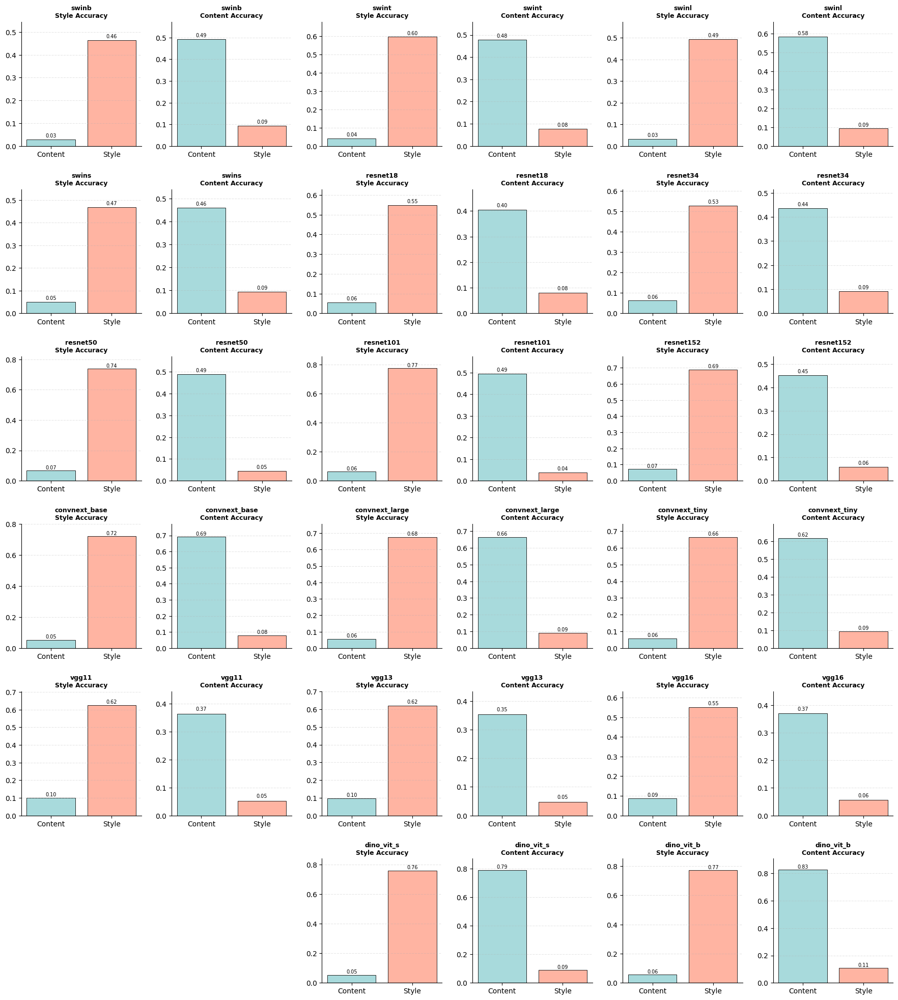

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

content_color = '#A8DADC'
style_color = '#FFB4A2'

# ---- GRID ----
n_cols = 6   # 3 models per row (each model = 2 plots)
n_rows = 6

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 20))
axes = axes.reshape(n_rows, n_cols)

model_idx = 0

for r in range(n_rows):
    for c in range(0, n_cols, 2):

        if model_idx >= len(model_names):
            break

        model_name = model_names[model_idx]
        out_dir = f"inference_outputs/mscoco_top100_retrieval_results/{model_name}/"
        content_path = out_dir + 'Content_units.npy'
        style_path = out_dir + 'Style_units.npy'

        ax_style = axes[r, c]
        ax_content = axes[r, c+1]

        if not os.path.exists(content_path) or not os.path.exists(style_path):
            ax_style.axis('off')
            ax_content.axis('off')
            model_idx += 1
            continue

        Content_units = np.load(content_path)
        Style_units = np.load(style_path)

        # ---------- STYLE ----------
        vals_left = [Content_units[0], Style_units[0]]
        bars_left = ax_style.bar(
            ['Content', 'Style'],
            vals_left,
            color=[content_color, style_color],
            edgecolor='black', linewidth=0.6
        )

        ax_style.set_title(f"{model_name}\nStyle Accuracy",
                           fontsize=9, fontweight='bold', pad=6)

        ax_style.set_ylim(0, max(vals_left) + 0.08)
        ax_style.grid(axis='y', linestyle='--', alpha=0.3)

        # ---------- CONTENT ----------
        vals_right = [Content_units[1], Style_units[1]]
        bars_right = ax_content.bar(
            ['Content', 'Style'],
            vals_right,
            color=[content_color, style_color],
            edgecolor='black', linewidth=0.6
        )

        ax_content.set_title(f"{model_name}\nContent Accuracy",
                             fontsize=9, fontweight='bold', pad=6)

        ax_content.set_ylim(0, max(vals_right) + 0.08)
        ax_content.grid(axis='y', linestyle='--', alpha=0.3)

        # ---------- ANNOTATIONS ----------
        for ax, bars in zip([ax_style, ax_content], [bars_left, bars_right]):
            for bar in bars:
                h = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                        f"{h:.2f}", ha='center', fontsize=7)

        # ---------- CLEANUP ----------
        for ax in [ax_style, ax_content]:
            for spine in ['top', 'right']:
                ax.spines[spine].set_visible(False)

        model_idx += 1

# ---- TURN OFF UNUSED AXES ----
for i in range(model_idx, n_rows * (n_cols // 2)):
    r = i // 3
    c = (i % 3) * 2
    axes[r, c].axis('off')
    axes[r, c+1].axis('off')

# ---- GLOBAL FORMATTING ----
plt.tight_layout(pad=2.0)
plt.savefig("all_models_grid_clean.png", dpi=200, bbox_inches='tight')
plt.show()

# Results 3b - MSCOCO Retrievals

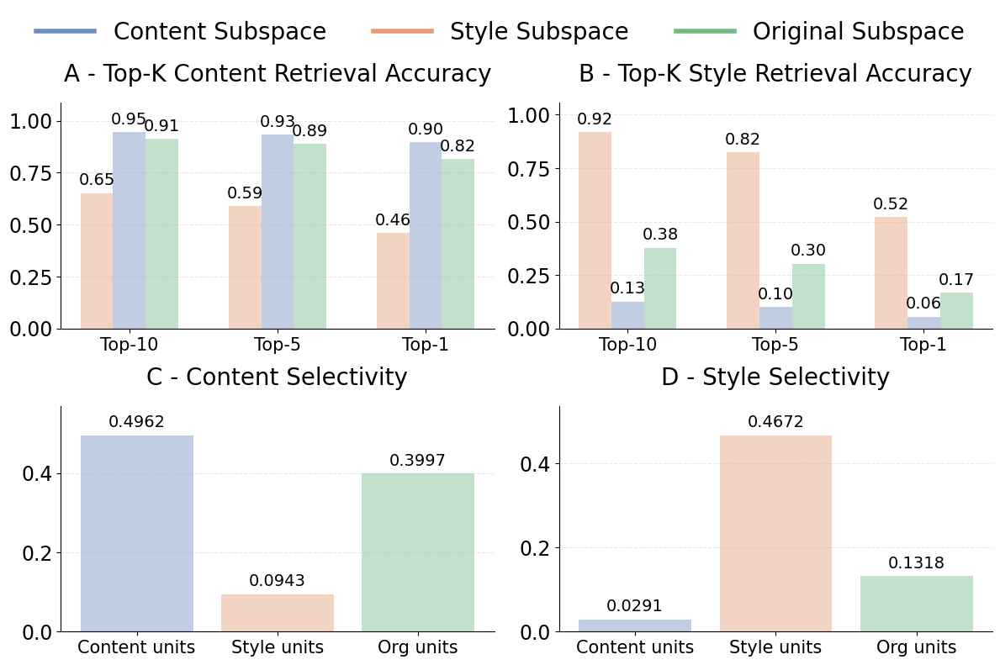

In [10]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import os

# -----------------------------
# Plot (2 x 2)
# -----------------------------

model_name = 'swinb'
base_dir = "inference_outputs/mscoco_retrieval_results/invertible/" + model_name

content_color = "#4C72B0"
style_color   = "#DD8452"
org_color     = "#55A868"

color_map = {
    "content": content_color,
    "style": style_color,
    "org": org_color
}

topks = [10, 5, 1]
unit_types = ["style", "content", "org"]

out_dir = f"inference_outputs/mscoco_top100_retrieval_results/invertible/{model_name}/"

Content_units = np.load(out_dir + 'Content_units.npy')
Style_units = np.load(out_dir + 'Style_units.npy')
original_units = np.load(out_dir + 'Org_units.npy')


def load_data(acc_type):
    data = {u: [] for u in unit_types}

    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)

            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)

    return data


content_data = load_data("content")
style_data   = load_data("style")

# -----------------------------
# Figure setup
# -----------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

x = np.arange(len(topks))
width = 0.22

# -----------------------------
# Plot 1: Content Top-K
# -----------------------------
ax = axes[0]

for i, unit in enumerate(unit_types):

    offset = (i - 1) * width
    vals = content_data[unit]

    bars = ax.bar(
        x + offset,
        vals,
        width,
        label=f"{unit.capitalize()} units",
        color=color_map[unit],
        alpha=0.35
    )

    for bar in bars:

        h = bar.get_height()

        ax.annotate(
            f"{h:.2f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                h
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=14
        )

ax.set_xticks(x)
ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'], fontsize=15)
ax.tick_params(axis='y', labelsize=17)
ax.set_title(
    "A - Top-K Content Retrieval Accuracy",
    fontsize=20,
    pad=18
)

ax.margins(y=0.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# -----------------------------
# Plot 2: Style Top-K
# -----------------------------
ax = axes[1]

for i, unit in enumerate(unit_types):

    offset = (i - 1) * width
    vals = style_data[unit]

    bars = ax.bar(
        x + offset,
        vals,
        width,
        color=color_map[unit],
        alpha=0.35
    )

    for bar in bars:

        h = bar.get_height()

        ax.annotate(
            f"{h:.2f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                h
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=14
        )

ax.set_xticks(x)
ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'], fontsize=15)
ax.tick_params(axis='y', labelsize=17)
ax.set_title(
    "B - Top-K Style Retrieval Accuracy",
    fontsize=20,
    pad=18
)

ax.margins(y=0.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# -----------------------------
# Plot 3: Content Selectivity
# -----------------------------
ax = axes[2]

vals_content = [
    Content_units[1],
    Style_units[1],
    original_units[1]
]

labels_content = [
    'Content units',
    'Style units',
    'Org units'
]

bars = ax.bar(
    np.arange(len(labels_content)),
    vals_content,
    alpha=0.35,
    color=[content_color, style_color, org_color]
)

ax.set_xticks(np.arange(len(labels_content)))
ax.set_xticklabels(labels_content, fontsize=15)

ax.set_title(
    'C - Content Selectivity',
    fontsize=20,
    pad=18
)

ax.margins(y=0.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.tick_params(axis='y', labelsize=17)
for bar in bars:

    h = bar.get_height()

    ax.annotate(
        f"{h:.4f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            h
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=14
    )

# -----------------------------
# Plot 4: Style Selectivity
# -----------------------------
ax = axes[3]

vals_style = [
    Content_units[0],
    Style_units[0],
    original_units[0]
]

labels_style = [
    'Content units',
    'Style units',
    'Org units'
]

bars = ax.bar(
    np.arange(len(labels_style)),
    vals_style,
    alpha=0.35,
    color=[content_color, style_color, org_color]
)

ax.set_xticks(np.arange(len(labels_style)))
ax.set_xticklabels(labels_style, fontsize=15)
ax.tick_params(axis='y', labelsize=17)
ax.set_title(
    'D - Style Selectivity',
    fontsize=20,
    pad=18
)

ax.margins(y=0.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)

for bar in bars:

    h = bar.get_height()

    ax.annotate(
        f"{h:.4f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            h
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=14
    )

# -----------------------------
# Cleanup
# -----------------------------
for ax in axes:

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# -----------------------------
# Legend
# -----------------------------
handles = [
    Line2D([0], [0], color=content_color, lw=4, alpha=0.8),
    Line2D([0], [0], color=style_color, lw=4, alpha=0.8),
    Line2D([0], [0], color=org_color, lw=4, alpha=0.8)
]

labels = [
    "Content Subspace",
    "Style Subspace",
    "Original Subspace"
]

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=3,
    frameon=False,
    fontsize=20,
    handlelength=2.5
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig(
    'neurips_2026_images/metric_plots_swinb.pdf',
    bbox_inches='tight'
)

plt.show()

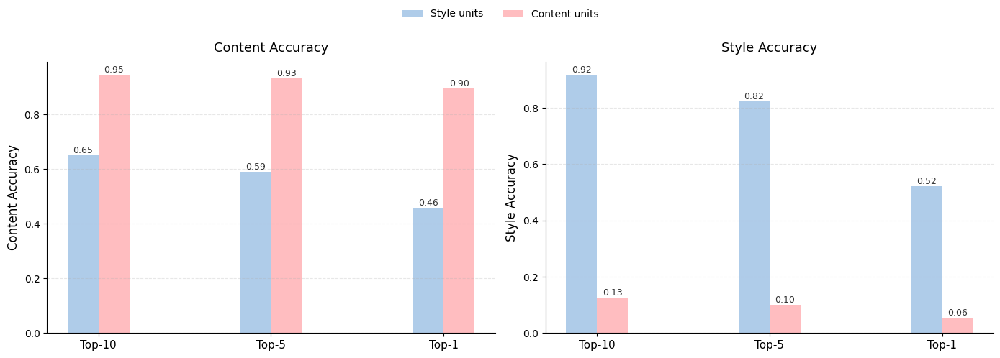

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

model_name = 'swinb'
base_dir = "inference_outputs/mscoco_retrieval_results/invertible/" + model_name

topks = [10, 5, 1]
unit_types = ["style", "content"]

# ---------- Load data ----------
def load_data(acc_type):
    data = {u: [] for u in unit_types}
    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)
    return data

content_data = load_data("content")
style_data   = load_data("style")

# ---------- Plot setup ----------
x = np.arange(len(topks))
width = 0.18

colors = {
    "style":   "#A7C7E7",
    "content": "#FFB6B9",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

plots = [
    (axes[0], content_data, "Content Accuracy"),
    (axes[1], style_data, "Style Accuracy")
]

for ax, data, title in plots:

    bars = []
    for i, unit in enumerate(unit_types):
        bars.append(
            ax.bar(
                x + (i - 0.5) * width,
                data[unit],
                width,
                label=f"{unit.capitalize()} units",
                color=colors[unit],
                alpha=0.9
            )
        )

    # axis formatting
    ax.set_xticks(x)
    ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'], fontsize=11)
    ax.set_ylabel(title, fontsize=12)
    ax.set_title(title, fontsize=13, pad=10)

    ax.grid(axis='y', linestyle='--', alpha=0.3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # annotations
    for group in bars:
        for bar in group:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                h,
                f"{h:.2f}",
                ha='center',
                va='bottom',
                fontsize=9,
                alpha=0.8
            )

# shared legend (clean look)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

/tmp/ipykernel_388469/555884649.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


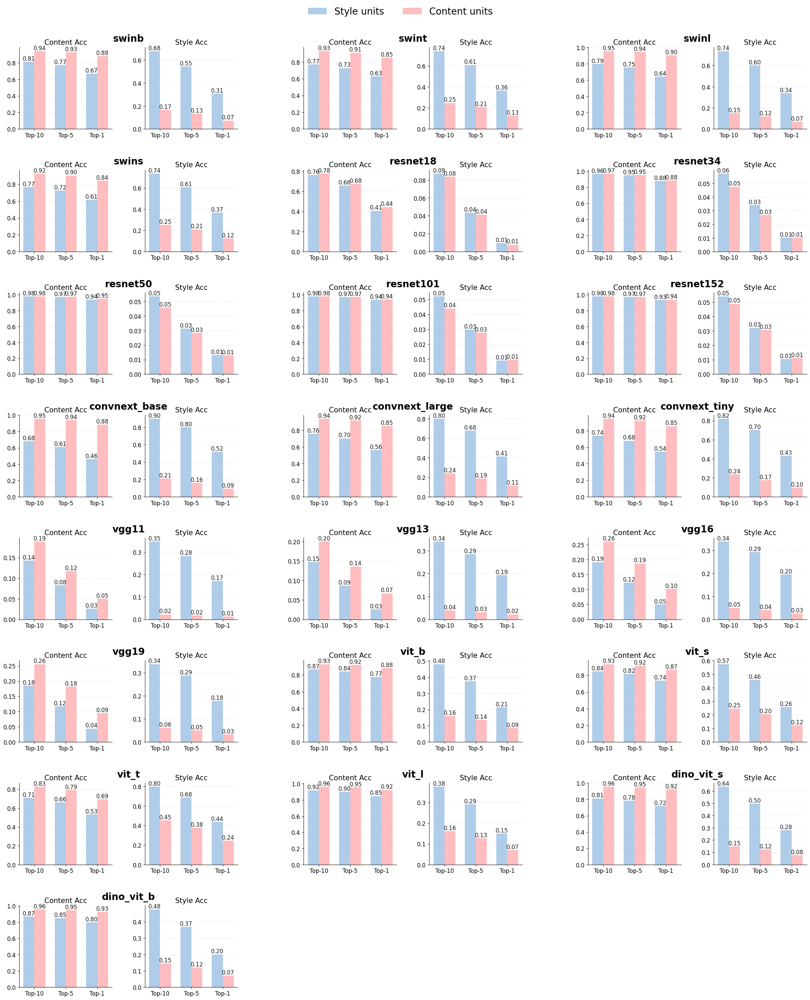

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Patch

# ---------------- GLOBAL FONT SETTINGS ----------------
mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 20,
})

# ---------------- MODELS ----------------
model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19','vit_b', 'vit_s', 'vit_t', 'vit_l',
    'dino_vit_s', 'dino_vit_b'
]

base_dir_template = "inference_outputs/mscoco_retrieval_results/orthogonal/{model}"
topks = [10, 5, 1]
unit_types = ["style", "content"]

colors = {
    "style": "#A7C7E7",
    "content": "#FFB6B9",
}

# ---------------- LOAD DATA ----------------
def load_data(model_name, acc_type):
    base_dir = base_dir_template.format(model=model_name)
    data = {u: [] for u in unit_types}

    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)

    return data




# ---------------- LAYOUT ----------------
n_models = len(model_names)
n_cols_pairs = 3        # model pairs per row
n_rows = 8              # 18 models → 6 rows

fig = plt.figure(figsize=(n_cols_pairs * 2 * 5, n_rows * 4.5))

# Outer grid: each cell holds one model (= 2 subplots)
outer = gridspec.GridSpec(n_rows, n_cols_pairs, figure=fig, hspace=0.5, wspace=0.3)

x = np.arange(len(topks))
width = 0.35

# ---------------- PLOTTING ----------------
for idx, model_name in enumerate(model_names):
    row = idx // n_cols_pairs
    col = idx % n_cols_pairs

    try:
        content_data = load_data(model_name, "content")
        style_data   = load_data(model_name, "style")
    except FileNotFoundError as e:
        print(f"[SKIP] {model_name}: {e}")
        continue

    # Inner grid: 1 row × 2 cols for this model's two subplots
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row, col],
        wspace=0.35
    )

    # ---- Shared model-name header via an invisible spanning axes ----
    header_ax = fig.add_subplot(outer[row, col])
    header_ax.set_title(model_name, fontsize=20, fontweight='bold', pad=12)
    header_ax.axis('off')

    plots = [
        (content_data, "Content Acc", inner[0]),
        (style_data,   "Style Acc",   inner[1]),
    ]

    for data, acc_label, spec in plots:
        ax = fig.add_subplot(spec)
        bars = []
        for i, unit in enumerate(unit_types):
            bars.append(
                ax.bar(
                    x + (i - 0.5) * width,
                    data[unit],
                    width,
                    label=f"{unit.capitalize()} units",
                    color=colors[unit],
                    alpha=0.9
                )
            )
        ax.set_xticks(x)
        ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'])
        ax.set_title(acc_label, pad=6)          # only acc type now
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        for group in bars:
            for bar in group:
                h = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h,
                    f"{h:.2f}",
                    ha='center', va='bottom',
                    fontsize=12, alpha=0.9
                )

legend_elements = [
    Patch(facecolor=colors["style"], alpha=0.9, label="Style units"),
    Patch(facecolor=colors["content"], alpha=0.9, label="Content units"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.92)
)

plt.tight_layout()
plt.savefig('neurips_2026_images/retrieval_orthogonal.pdf')
plt.show()

/tmp/ipykernel_388469/3233635009.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


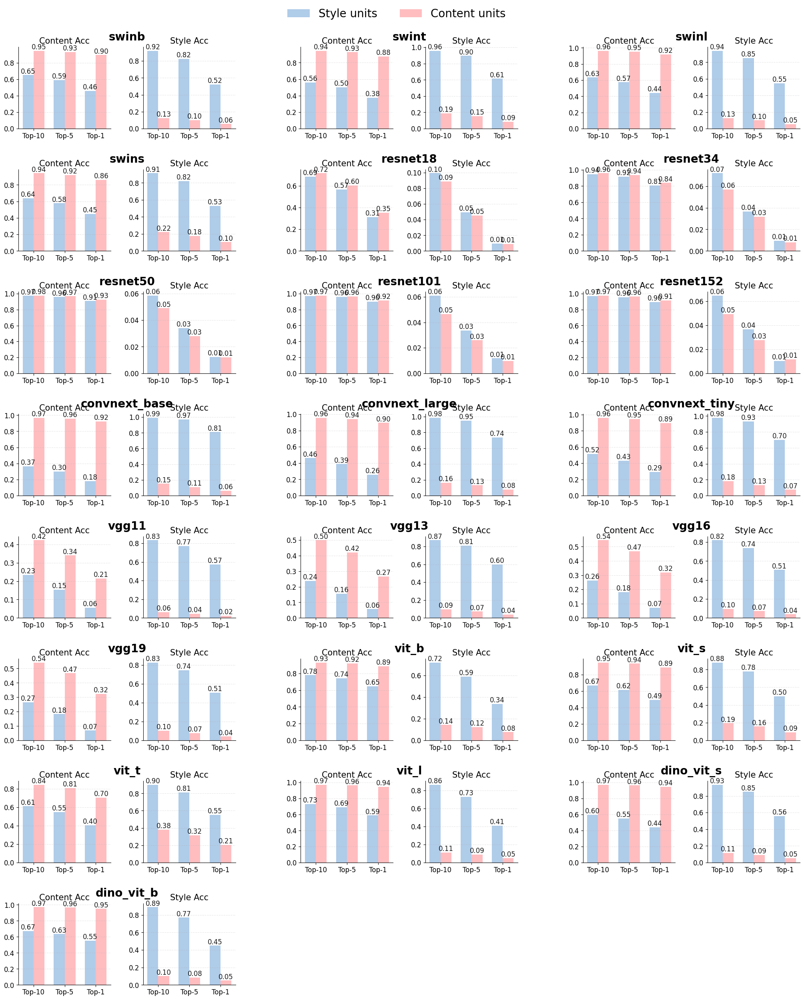

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Patch

# ---------------- GLOBAL FONT SETTINGS ----------------
mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 20,
})

# ---------------- MODELS ----------------
model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19','vit_b', 'vit_s', 'vit_t', 'vit_l',
    'dino_vit_s', 'dino_vit_b'
]

base_dir_template = "inference_outputs/mscoco_retrieval_results/invertible/{model}"
topks = [10, 5, 1]
unit_types = ["style", "content"]

colors = {
    "style": "#A7C7E7",
    "content": "#FFB6B9",
}

# ---------------- LOAD DATA ----------------
def load_data(model_name, acc_type):
    base_dir = base_dir_template.format(model=model_name)
    data = {u: [] for u in unit_types}

    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)

    return data




# ---------------- LAYOUT ----------------
n_models = len(model_names)
n_cols_pairs = 3        # model pairs per row
n_rows = 8              # 18 models → 6 rows

fig = plt.figure(figsize=(n_cols_pairs * 2 * 4.2, n_rows * 3.8))

# Outer grid: each cell holds one model (= 2 subplots)
outer = gridspec.GridSpec(n_rows, n_cols_pairs, figure=fig, hspace=0.5, wspace=0.3)

x = np.arange(len(topks))
width = 0.35

# ---------------- PLOTTING ----------------
for idx, model_name in enumerate(model_names):
    row = idx // n_cols_pairs
    col = idx % n_cols_pairs

    try:
        content_data = load_data(model_name, "content")
        style_data   = load_data(model_name, "style")
    except FileNotFoundError as e:
        print(f"[SKIP] {model_name}: {e}")
        continue

    # Inner grid: 1 row × 2 cols for this model's two subplots
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row, col],
        wspace=0.35
    )

    # ---- Shared model-name header via an invisible spanning axes ----
    header_ax = fig.add_subplot(outer[row, col])
    header_ax.set_title(model_name, fontsize=20, fontweight='bold', pad=12)
    header_ax.axis('off')

    plots = [
        (content_data, "Content Acc", inner[0]),
        (style_data,   "Style Acc",   inner[1]),
    ]

    for data, acc_label, spec in plots:
        ax = fig.add_subplot(spec)
        bars = []
        for i, unit in enumerate(unit_types):
            bars.append(
                ax.bar(
                    x + (i - 0.5) * width,
                    data[unit],
                    width,
                    label=f"{unit.capitalize()} units",
                    color=colors[unit],
                    alpha=0.9
                )
            )
        ax.set_xticks(x)
        ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'])
        ax.set_title(acc_label, pad=6)          # only acc type now
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        for group in bars:
            for bar in group:
                h = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h,
                    f"{h:.2f}",
                    ha='center', va='bottom',
                    fontsize=12, alpha=0.9
                )

legend_elements = [
    Patch(facecolor=colors["style"], alpha=0.9, label="Style units"),
    Patch(facecolor=colors["content"], alpha=0.9, label="Content units"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.92)
)

plt.tight_layout()
plt.savefig('neurips_2026_images/retrieval_invertible.pdf')
plt.show()

/tmp/ipykernel_388469/1095775353.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


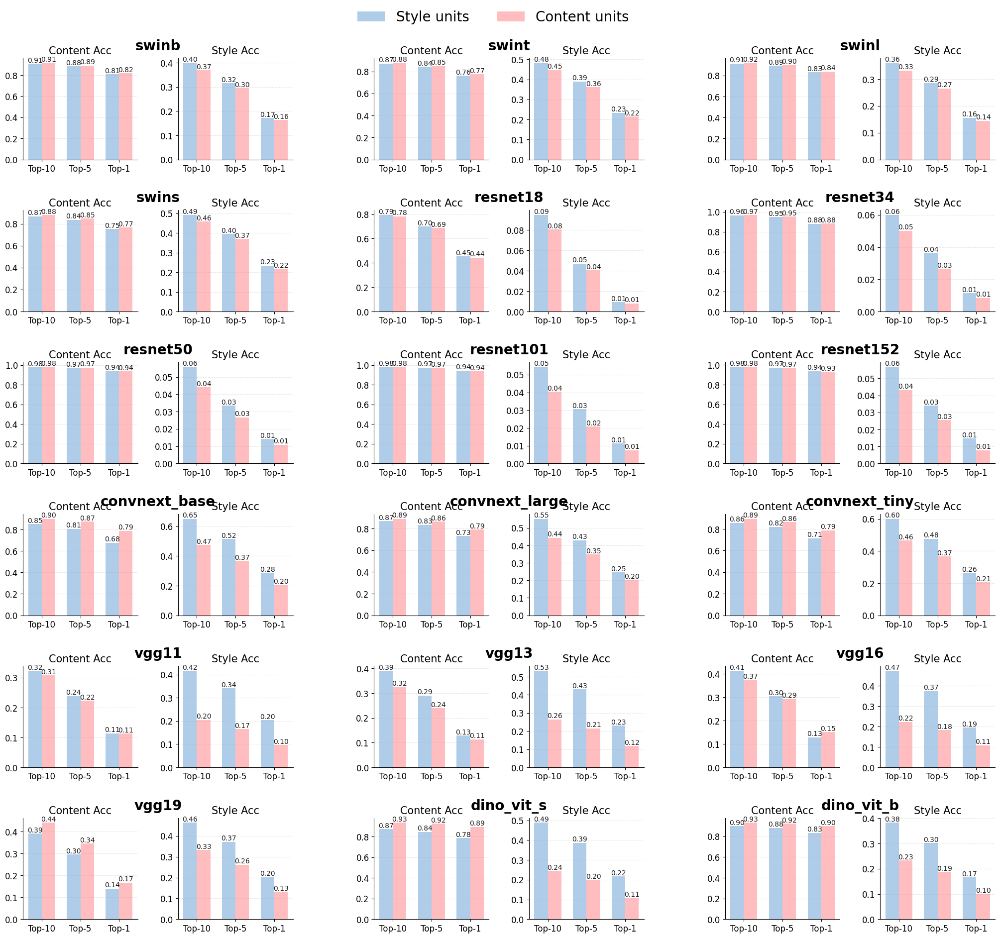

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Patch

# ---------------- GLOBAL FONT SETTINGS ----------------
mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 20,
})

# ---------------- MODELS ----------------
model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19',
    'dino_vit_s', 'dino_vit_b'
]

base_dir_template = "inference_outputs/mscoco_retrieval_results/permutation/{model}"
topks = [10, 5, 1]
unit_types = ["style", "content"]

colors = {
    "style": "#A7C7E7",
    "content": "#FFB6B9",
}

# ---------------- LOAD DATA ----------------
def load_data(model_name, acc_type):
    base_dir = base_dir_template.format(model=model_name)
    data = {u: [] for u in unit_types}

    for unit in unit_types:
        for k in topks:
            fname = f"{unit}_units_{acc_type}_acc_{k}.npy"
            fpath = os.path.join(base_dir, fname)
            val = np.load(fpath, allow_pickle=True).item()
            data[unit].append(val)

    return data




# ---------------- LAYOUT ----------------
n_models = len(model_names)
n_cols_pairs = 3        # model pairs per row
n_rows = 8              # 18 models → 6 rows

fig = plt.figure(figsize=(n_cols_pairs * 2 * 4.2, n_rows * 3.8))

# Outer grid: each cell holds one model (= 2 subplots)
outer = gridspec.GridSpec(n_rows, n_cols_pairs, figure=fig, hspace=0.5, wspace=0.3)

x = np.arange(len(topks))
width = 0.35

# ---------------- PLOTTING ----------------
for idx, model_name in enumerate(model_names):
    row = idx // n_cols_pairs
    col = idx % n_cols_pairs

    try:
        content_data = load_data(model_name, "content")
        style_data   = load_data(model_name, "style")
    except FileNotFoundError as e:
        print(f"[SKIP] {model_name}: {e}")
        continue

    # Inner grid: 1 row × 2 cols for this model's two subplots
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row, col],
        wspace=0.35
    )

    # ---- Shared model-name header via an invisible spanning axes ----
    header_ax = fig.add_subplot(outer[row, col])
    header_ax.set_title(model_name, fontsize=20, fontweight='bold', pad=12)
    header_ax.axis('off')

    plots = [
        (content_data, "Content Acc", inner[0]),
        (style_data,   "Style Acc",   inner[1]),
    ]

    for data, acc_label, spec in plots:
        ax = fig.add_subplot(spec)
        bars = []
        for i, unit in enumerate(unit_types):
            bars.append(
                ax.bar(
                    x + (i - 0.5) * width,
                    data[unit],
                    width,
                    label=f"{unit.capitalize()} units",
                    color=colors[unit],
                    alpha=0.9
                )
            )
        ax.set_xticks(x)
        ax.set_xticklabels(['Top-10', 'Top-5', 'Top-1'])
        ax.set_title(acc_label, pad=6)          # only acc type now
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        for group in bars:
            for bar in group:
                h = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h,
                    f"{h:.2f}",
                    ha='center', va='bottom',
                    fontsize=10, alpha=0.9
                )

legend_elements = [
    Patch(facecolor=colors["style"], alpha=0.9, label="Style units"),
    Patch(facecolor=colors["content"], alpha=0.9, label="Content units"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.92)
)

plt.tight_layout()
plt.savefig('neurips_2026_images/retrieval_permutation.pdf')
plt.show()

# Results 3a - Sanity Test on MSCOCO Invertible Transforms

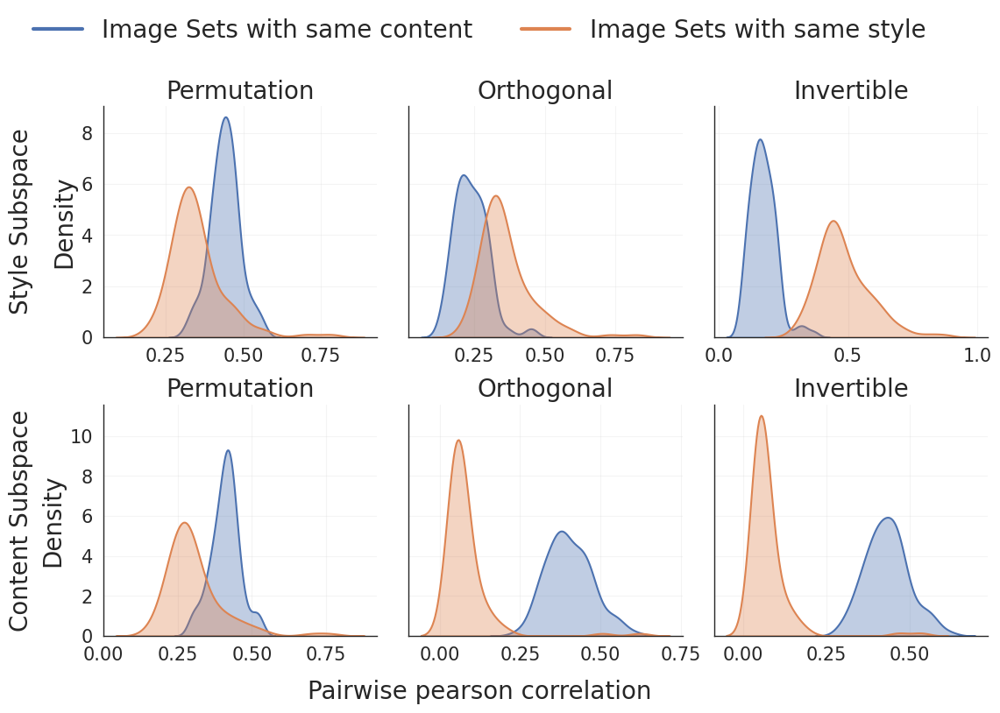

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

# --- Style ---
sns.set_theme(style="white", context="paper")

COLOR_CONTENT = "#4C72B0"
COLOR_STYLE   = "#DD8452"

model_name = 'swinb'
types = ['permutation', 'orthogonal', 'invertible']

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=False, sharey='row')

for col, t in enumerate(types):
    # --- Load ---
    corr_style_c = np.load(f'inference_outputs/mscoco_sanity_tests/{t}/{model_name}/corr_style_c.npy')
    corr_style_s = np.load(f'inference_outputs/mscoco_sanity_tests/{t}/{model_name}/corr_style_s.npy')
    corr_content_c = np.load(f'inference_outputs/mscoco_sanity_tests/{t}/{model_name}/corr_content_c.npy')
    corr_content_s = np.load(f'inference_outputs/mscoco_sanity_tests/{t}/{model_name}/corr_content_s.npy')

    # =====================
    # Row 0: Style Units
    # =====================
    ax = axes[0, col]

    sns.kdeplot(corr_style_c, ax=ax, color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
    sns.kdeplot(corr_style_s, ax=ax, color=COLOR_STYLE,   fill=True, alpha=0.35, linewidth=1.5)

    if col == 0:
        ax.set_ylabel("Density", fontsize=20)
    else:
        ax.set_ylabel("")

    ax.set_title(t.capitalize(), pad=6, fontsize=20)
    # ax.set_xlabel("Pairwise correlation (same style images)")
    ax.grid(alpha=0.2)
    ax.tick_params(axis='both', which='major', labelsize=15)
    sns.despine(ax=ax)

    # =====================
    # Row 1: Content Units
    # =====================
    ax = axes[1, col]

    sns.kdeplot(corr_content_c, ax=ax, color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
    sns.kdeplot(corr_content_s, ax=ax, color=COLOR_STYLE,   fill=True, alpha=0.35, linewidth=1.5)
    
    if col == 0:
        ax.set_ylabel("Density", fontsize=20)
    else:
        ax.set_ylabel("")
    
    # ADD THIS LINE 👇
    ax.set_title(t.capitalize(), pad=6, fontsize=20)
    
    ax.grid(alpha=0.2)
    ax.tick_params(axis='both', which='major', labelsize=15)
    sns.despine(ax=ax)

# --- Row labels (cleaner than repeating titles) ---
axes[0, 0].text(-0.3, 0.5, "Style Subspace", va='center', ha='center',
                rotation=90, fontsize=20, transform=axes[0, 0].transAxes)

axes[1, 0].text(-0.3, 0.5, "Content Subspace", va='center', ha='center',
                rotation=90, fontsize=20, transform=axes[1, 0].transAxes)

# --- Global title ---
# fig.suptitle(
#     model_name.upper(),
#     fontsize=14,
#     fontweight='bold',
#     y=1.02
# )

# --- Shared legend ---
legend_elements = [
    Line2D([0], [0], color=COLOR_CONTENT, lw=3, label='Image Sets with same content'),
    Line2D([0], [0], color=COLOR_STYLE,   lw=3, label='Image Sets with same style')
]

fig.legend(
    handles=legend_elements,
    loc='upper center',   # moved to top
    ncol=2,
    frameon=False,
    fontsize=20,
    bbox_to_anchor=(0.5, 1.02)  # slightly above the figure
)

# adjust layout to make space for legend at top
plt.tight_layout(rect=[0.05, 0.05, 1, 0.92])
fig.supxlabel("Pairwise pearson correlation", fontsize=20)
plt.savefig('neurips_2026_images/distribution_comp_main.pdf')

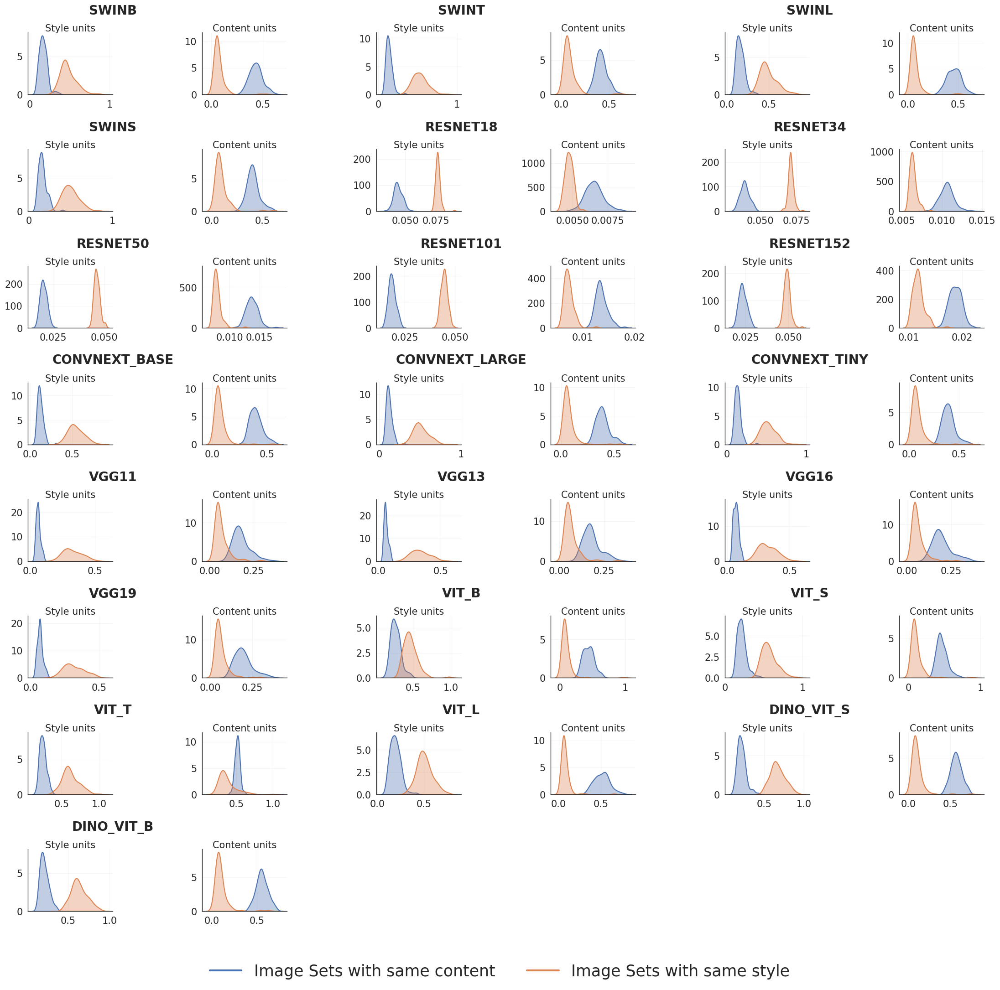

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os

# --- Style ---
sns.set_theme(style="white", context="paper")

# Consistent colors
COLOR_CONTENT = "#4C72B0"  # blue
COLOR_STYLE   = "#DD8452"  # orange

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19', 'vit_b', 'vit_s', 'vit_t', 'vit_l',
    'dino_vit_s', 'dino_vit_b'
]

n_models = len(model_names)
n_cols = 6
n_rows = int(np.ceil(n_models / (n_cols // 2)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 2.8))
axes = axes.reshape(n_rows, n_cols)


for i, model_name in enumerate(model_names):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2

    ax_style = axes[row, col]
    ax_content = axes[row, col + 1]

    base = f'inference_outputs/mscoco_sanity_tests/invertible/{model_name}'

    try:
        corr_style_c   = np.load(os.path.join(base, 'corr_style_c.npy'))
        corr_style_s   = np.load(os.path.join(base, 'corr_style_s.npy'))
        corr_content_c = np.load(os.path.join(base, 'corr_content_c.npy'))
        corr_content_s = np.load(os.path.join(base, 'corr_content_s.npy'))

                # --- Style ---
        sns.kdeplot(corr_style_c, ax=ax_style,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_style_s, ax=ax_style,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_style.set_title("Style units", pad=2, fontsize=15)

        # --- Content ---
        sns.kdeplot(corr_content_c, ax=ax_content,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_content_s, ax=ax_content,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_content.set_title("Content units", pad=2, fontsize=15)

        # Clean axes
        for ax in (ax_style, ax_content):
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.grid(alpha=0.2)
            sns.despine(ax=ax)

            # Larger x/y tick labels
            ax.tick_params(axis='both', labelsize=15)

        # Model label
        ax_style.annotate(
            model_name.upper(),
            xy=(1.0, 1.25),
            xycoords='axes fraction',
            ha='center',
            va='bottom',
            fontsize=20,
            fontweight='bold'
        )

    except FileNotFoundError:
        for ax in (ax_style, ax_content):
            ax.text(0.5, 0.5, f"Missing\n{model_name}",
                    ha='center', va='center',
                    transform=ax.transAxes,
                    fontsize=8, color='red')
            ax.axis('off')

# Turn off unused axes
for i in range(n_models, n_rows * (n_cols // 2)):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2
    axes[row, col].axis('off')
    axes[row, col + 1].axis('off')

# --- SINGLE GLOBAL LEGEND ---
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color=COLOR_CONTENT, lw=3, label='Image Sets with same content'),
    Line2D([0], [0], color=COLOR_STYLE, lw=3, label='Image Sets with same style')
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=2,
    frameon=False,
    fontsize=25,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig('neurips_2026_images/distribution_invertible.pdf')
plt.show()

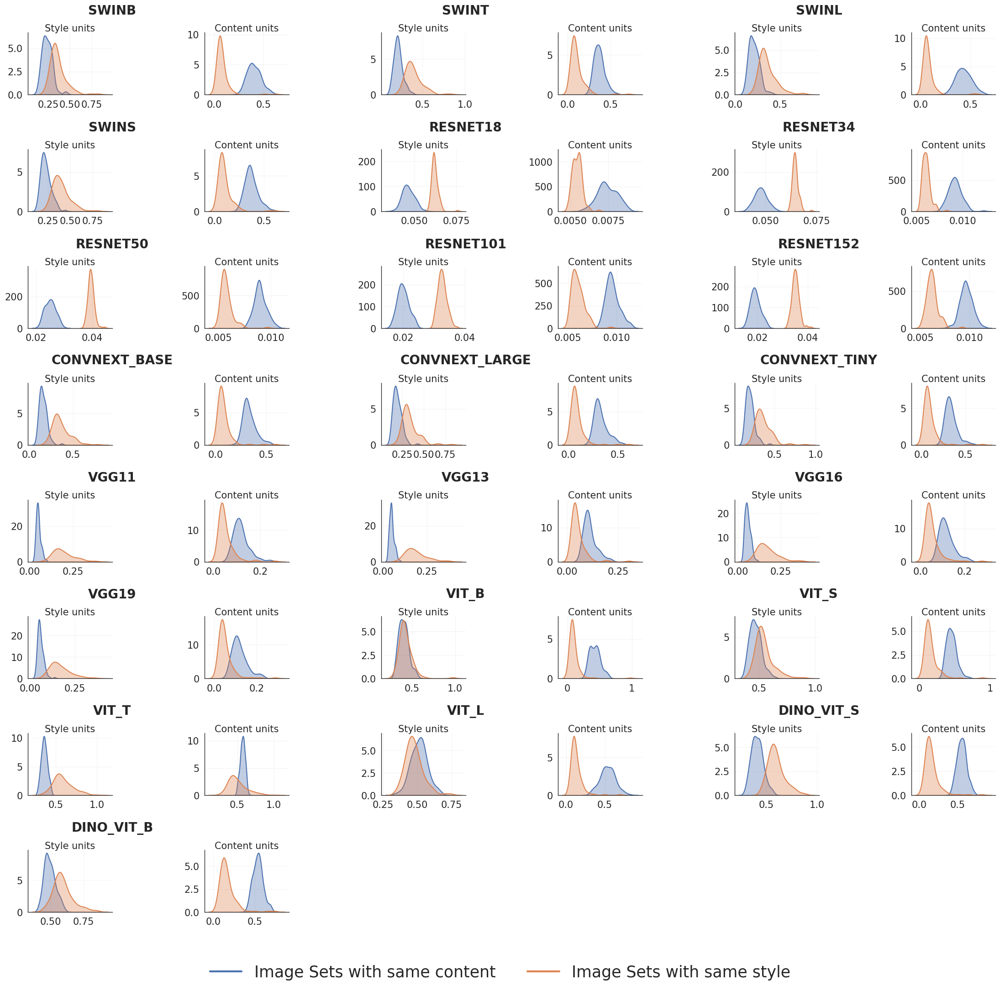

In [51]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os

# --- Style ---
sns.set_theme(style="white", context="paper")

# Consistent colors
COLOR_CONTENT = "#4C72B0"  # blue
COLOR_STYLE   = "#DD8452"  # orange

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19','vit_b', 'vit_s', 'vit_t', 'vit_l',
    'dino_vit_s', 'dino_vit_b'
]

n_models = len(model_names)
n_cols = 6
n_rows = int(np.ceil(n_models / (n_cols // 2)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 2.8))
axes = axes.reshape(n_rows, n_cols)


for i, model_name in enumerate(model_names):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2

    ax_style = axes[row, col]
    ax_content = axes[row, col + 1]

    base = f'inference_outputs/mscoco_sanity_tests/orthogonal/{model_name}'

    try:
        corr_style_c   = np.load(os.path.join(base, 'corr_style_c.npy'))
        corr_style_s   = np.load(os.path.join(base, 'corr_style_s.npy'))
        corr_content_c = np.load(os.path.join(base, 'corr_content_c.npy'))
        corr_content_s = np.load(os.path.join(base, 'corr_content_s.npy'))

                # --- Style ---
        sns.kdeplot(corr_style_c, ax=ax_style,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_style_s, ax=ax_style,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_style.set_title("Style units", pad=2, fontsize=15)

        # --- Content ---
        sns.kdeplot(corr_content_c, ax=ax_content,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_content_s, ax=ax_content,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_content.set_title("Content units", pad=2, fontsize=15)

        # Clean axes
        for ax in (ax_style, ax_content):
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.grid(alpha=0.2)
            sns.despine(ax=ax)

            # Larger x/y tick labels
            ax.tick_params(axis='both', labelsize=15)

        # Model label
        ax_style.annotate(
            model_name.upper(),
            xy=(1.0, 1.25),
            xycoords='axes fraction',
            ha='center',
            va='bottom',
            fontsize=20,
            fontweight='bold'
        )

    except FileNotFoundError:
        for ax in (ax_style, ax_content):
            ax.text(0.5, 0.5, f"Missing\n{model_name}",
                    ha='center', va='center',
                    transform=ax.transAxes,
                    fontsize=8, color='red')
            ax.axis('off')

# Turn off unused axes
for i in range(n_models, n_rows * (n_cols // 2)):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2
    axes[row, col].axis('off')
    axes[row, col + 1].axis('off')

# --- SINGLE GLOBAL LEGEND ---
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color=COLOR_CONTENT, lw=3, label='Image Sets with same content'),
    Line2D([0], [0], color=COLOR_STYLE, lw=3, label='Image Sets with same style')
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=2,
    frameon=False,
    fontsize=25,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig('neurips_2026_images/distribution_orthogonal.pdf')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os

# --- Style ---
sns.set_theme(style="white", context="paper")

# Consistent colors
COLOR_CONTENT = "#4C72B0"  # blue
COLOR_STYLE   = "#DD8452"  # orange

model_names = [
    'swinb', 'swint', 'swinl', 'swins',
    'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152',
    'convnext_base', 'convnext_large', 'convnext_tiny',
    'vgg11', 'vgg13', 'vgg16', 'vgg19','vit_b', 'vit_s', 'vit_t', 'vit_l',
    'dino_vit_s', 'dino_vit_b'
]

n_models = len(model_names)
n_cols = 6
n_rows = int(np.ceil(n_models / (n_cols // 2)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 2.8))
axes = axes.reshape(n_rows, n_cols)


for i, model_name in enumerate(model_names):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2

    ax_style = axes[row, col]
    ax_content = axes[row, col + 1]

    base = f'inference_outputs/mscoco_sanity_tests/permutation/{model_name}'

    try:
        corr_style_c   = np.load(os.path.join(base, 'corr_style_c.npy'))
        corr_style_s   = np.load(os.path.join(base, 'corr_style_s.npy'))
        corr_content_c = np.load(os.path.join(base, 'corr_content_c.npy'))
        corr_content_s = np.load(os.path.join(base, 'corr_content_s.npy'))

                # --- Style ---
        sns.kdeplot(corr_style_c, ax=ax_style,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_style_s, ax=ax_style,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_style.set_title("Style units", pad=2, fontsize=15)

        # --- Content ---
        sns.kdeplot(corr_content_c, ax=ax_content,
                    color=COLOR_CONTENT, fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(corr_content_s, ax=ax_content,
                    color=COLOR_STYLE, fill=True, alpha=0.35, linewidth=1.5)
        ax_content.set_title("Content units", pad=2, fontsize=15)

        # Clean axes
        for ax in (ax_style, ax_content):
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.grid(alpha=0.2)
            sns.despine(ax=ax)

            # Larger x/y tick labels
            ax.tick_params(axis='both', labelsize=15)

        # Model label
        ax_style.annotate(
            model_name.upper(),
            xy=(1.0, 1.25),
            xycoords='axes fraction',
            ha='center',
            va='bottom',
            fontsize=20,
            fontweight='bold'
        )

    except FileNotFoundError:
        for ax in (ax_style, ax_content):
            ax.text(0.5, 0.5, f"Missing\n{model_name}",
                    ha='center', va='center',
                    transform=ax.transAxes,
                    fontsize=8, color='red')
            ax.axis('off')

# Turn off unused axes
for i in range(n_models, n_rows * (n_cols // 2)):
    row = i // (n_cols // 2)
    col = (i % (n_cols // 2)) * 2
    axes[row, col].axis('off')
    axes[row, col + 1].axis('off')

# --- SINGLE GLOBAL LEGEND ---
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color=COLOR_CONTENT, lw=3, label='Image Sets with same content'),
    Line2D([0], [0], color=COLOR_STYLE, lw=3, label='Image Sets with same style')
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=2,
    frameon=False,
    fontsize=25,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig('neurips_2026_images/distribution_permutation.pdf')
plt.show()